In [1]:
import pandas as pd
import numpy as np

In [2]:
from pathlib import Path

data = Path("home-credit-default-risk")

In [3]:
application_df = pd.read_csv(data / "application_train.csv")
application_test_df = pd.read_csv(data / "application_test.csv")
bureau_df = pd.read_csv(data / "bureau.csv")
bureau_balance_df = pd.read_csv(data / "bureau_balance.csv")
previous_application_df = pd.read_csv(data / "previous_application.csv")
pos_cash_df = pd.read_csv(data / "POS_CASH_balance.csv")
credit_card_df = pd.read_csv(data / "credit_card_balance.csv")
installments_df = pd.read_csv(data / "installments_payments.csv")
sample_submission_df = pd.read_csv(data / "sample_submission.csv")


columns_description_df = pd.read_csv(
    data / "HomeCredit_columns_description.csv", encoding="latin-1", index_col=0
)

In [4]:
frames = {
    "application_train": application_df,
    "application_test": application_test_df,
    "bureau": bureau_df,
    "bureau_balance": bureau_balance_df,
    "previous_application": previous_application_df,
    "pos_cash": pos_cash_df,
    "credit_card": credit_card_df,
    "installments": installments_df,
    "sample_submission": sample_submission_df,
    "columns_description": columns_description_df,
}

for name, df in frames.items():
    mem = df.memory_usage(deep=True).sum() / 1e9
    print(f"{name:22} {df.shape[0]:>9,} rows  {df.shape[1]:>4} cols  {mem:5.2f} GB")

application_train        307,511 rows   122 cols   0.34 GB
application_test          48,744 rows   121 cols   0.05 GB
bureau                 1,716,428 rows    17 cols   0.28 GB
bureau_balance         27,299,925 rows     3 cols   0.68 GB
previous_application   1,670,214 rows    37 cols   0.70 GB
pos_cash               10,001,358 rows     8 cols   0.70 GB
credit_card            3,840,312 rows    23 cols   0.73 GB
installments           13,605,401 rows     8 cols   0.87 GB
sample_submission         48,744 rows     2 cols   0.00 GB
columns_description          219 rows     4 cols   0.00 GB


In [5]:
application_df.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [6]:
application_test_df.head()

,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100001,Cash loans,F,N,Y,0,135000.0,568800.0,20560.5,450000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
1,100005,Cash loans,M,N,Y,0,99000.0,222768.0,17370.0,180000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,3.0
2,100013,Cash loans,M,Y,Y,0,202500.0,663264.0,69777.0,630000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,1.0,4.0
3,100028,Cash loans,F,N,Y,2,315000.0,1575000.0,49018.5,1575000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,3.0
4,100038,Cash loans,M,Y,N,1,180000.0,625500.0,32067.0,625500.0,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
bureau_df.head()

,SK_ID_CURR,SK_ID_BUREAU,CREDIT_ACTIVE,CREDIT_CURRENCY,DAYS_CREDIT,CREDIT_DAY_OVERDUE,DAYS_CREDIT_ENDDATE,DAYS_ENDDATE_FACT,AMT_CREDIT_MAX_OVERDUE,CNT_CREDIT_PROLONG,AMT_CREDIT_SUM,AMT_CREDIT_SUM_DEBT,AMT_CREDIT_SUM_LIMIT,AMT_CREDIT_SUM_OVERDUE,CREDIT_TYPE,DAYS_CREDIT_UPDATE,AMT_ANNUITY
0,215354,5714462,Closed,currency 1,-497,0,-153.0,-153.0,NaN,0,91323.0,0.0,NaN,0.0,Consumer credit,-131,NaN
1,215354,5714463,Active,currency 1,-208,0,1075.0,NaN,NaN,0,225000.0,171342.0,NaN,0.0,Credit card,-20,NaN
2,215354,5714464,Active,currency 1,-203,0,528.0,NaN,NaN,0,464323.5,NaN,NaN,0.0,Consumer credit,-16,NaN
3,215354,5714465,Active,currency 1,-203,0,NaN,NaN,NaN,0,90000.0,NaN,NaN,0.0,Credit card,-16,NaN
4,215354,5714466,Active,currency 1,-629,0,1197.0,NaN,77674.5,0,2700000.0,NaN,NaN,0.0,Consumer credit,-21,NaN


In [8]:
bureau_balance_df.head()

,SK_ID_BUREAU,MONTHS_BALANCE,STATUS
0,5715448,0,C
1,5715448,-1,C
2,5715448,-2,C
3,5715448,-3,C
4,5715448,-4,C


In [9]:
previous_application_df.head()

,SK_ID_PREV,SK_ID_CURR,NAME_CONTRACT_TYPE,AMT_ANNUITY,AMT_APPLICATION,AMT_CREDIT,AMT_DOWN_PAYMENT,AMT_GOODS_PRICE,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,...,NAME_SELLER_INDUSTRY,CNT_PAYMENT,NAME_YIELD_GROUP,PRODUCT_COMBINATION,DAYS_FIRST_DRAWING,DAYS_FIRST_DUE,DAYS_LAST_DUE_1ST_VERSION,DAYS_LAST_DUE,DAYS_TERMINATION,NFLAG_INSURED_ON_APPROVAL
0,2030495,271877,Consumer loans,1730.430,17145.0,17145.0,0.0,17145.0,SATURDAY,15,...,Connectivity,12.0,middle,POS mobile with interest,365243.0,-42.0,300.0,-42.0,-37.0,0.0
1,2802425,108129,Cash loans,25188.615,607500.0,679671.0,NaN,607500.0,THURSDAY,11,...,XNA,36.0,low_action,Cash X-Sell: low,365243.0,-134.0,916.0,365243.0,365243.0,1.0
2,2523466,122040,Cash loans,15060.735,112500.0,136444.5,NaN,112500.0,TUESDAY,11,...,XNA,12.0,high,Cash X-Sell: high,365243.0,-271.0,59.0,365243.0,365243.0,1.0
3,2819243,176158,Cash loans,47041.335,450000.0,470790.0,NaN,450000.0,MONDAY,7,...,XNA,12.0,middle,Cash X-Sell: middle,365243.0,-482.0,-152.0,-182.0,-177.0,1.0
4,1784265,202054,Cash loans,31924.395,337500.0,404055.0,NaN,337500.0,THURSDAY,9,...,XNA,24.0,high,Cash Street: high,NaN,NaN,NaN,NaN,NaN,NaN


In [10]:
pos_cash_df.head()

,SK_ID_PREV,SK_ID_CURR,MONTHS_BALANCE,CNT_INSTALMENT,CNT_INSTALMENT_FUTURE,NAME_CONTRACT_STATUS,SK_DPD,SK_DPD_DEF
0,1803195,182943,-31,48.0,45.0,Active,0,0
1,1715348,367990,-33,36.0,35.0,Active,0,0
2,1784872,397406,-32,12.0,9.0,Active,0,0
3,1903291,269225,-35,48.0,42.0,Active,0,0
4,2341044,334279,-35,36.0,35.0,Active,0,0


In [11]:
credit_card_df.head()

,SK_ID_PREV,SK_ID_CURR,MONTHS_BALANCE,AMT_BALANCE,AMT_CREDIT_LIMIT_ACTUAL,AMT_DRAWINGS_ATM_CURRENT,AMT_DRAWINGS_CURRENT,AMT_DRAWINGS_OTHER_CURRENT,AMT_DRAWINGS_POS_CURRENT,AMT_INST_MIN_REGULARITY,...,AMT_RECIVABLE,AMT_TOTAL_RECEIVABLE,CNT_DRAWINGS_ATM_CURRENT,CNT_DRAWINGS_CURRENT,CNT_DRAWINGS_OTHER_CURRENT,CNT_DRAWINGS_POS_CURRENT,CNT_INSTALMENT_MATURE_CUM,NAME_CONTRACT_STATUS,SK_DPD,SK_DPD_DEF
0,2562384,378907,-6,56.970,135000,0.0,877.5,0.0,877.5,1700.325,...,0.000,0.000,0.0,1,0.0,1.0,35.0,Active,0,0
1,2582071,363914,-1,63975.555,45000,2250.0,2250.0,0.0,0.0,2250.000,...,64875.555,64875.555,1.0,1,0.0,0.0,69.0,Active,0,0
2,1740877,371185,-7,31815.225,450000,0.0,0.0,0.0,0.0,2250.000,...,31460.085,31460.085,0.0,0,0.0,0.0,30.0,Active,0,0
3,1389973,337855,-4,236572.110,225000,2250.0,2250.0,0.0,0.0,11795.760,...,233048.970,233048.970,1.0,1,0.0,0.0,10.0,Active,0,0
4,1891521,126868,-1,453919.455,450000,0.0,11547.0,0.0,11547.0,22924.890,...,453919.455,453919.455,0.0,1,0.0,1.0,101.0,Active,0,0


In [12]:
installments_df.head()

,SK_ID_PREV,SK_ID_CURR,NUM_INSTALMENT_VERSION,NUM_INSTALMENT_NUMBER,DAYS_INSTALMENT,DAYS_ENTRY_PAYMENT,AMT_INSTALMENT,AMT_PAYMENT
0,1054186,161674,1.0,6,-1180.0,-1187.0,6948.360,6948.360
1,1330831,151639,0.0,34,-2156.0,-2156.0,1716.525,1716.525
2,2085231,193053,2.0,1,-63.0,-63.0,25425.000,25425.000
3,2452527,199697,1.0,3,-2418.0,-2426.0,24350.130,24350.130
4,2714724,167756,1.0,2,-1383.0,-1366.0,2165.040,2160.585


In [13]:
sample_submission_df.head()

,SK_ID_CURR,TARGET
0,100001,0.5
1,100005,0.5
2,100013,0.5
3,100028,0.5
4,100038,0.5


In [14]:
columns_description_df.head()

,Table,Row,Description,Special
1,application_{train|test}.csv,SK_ID_CURR,ID of loan in our sample,NaN
2,application_{train|test}.csv,TARGET,Target variable (1 - client with payment diffi...,NaN
5,application_{train|test}.csv,NAME_CONTRACT_TYPE,Identification if loan is cash or revolving,NaN
6,application_{train|test}.csv,CODE_GENDER,Gender of the client,NaN
7,application_{train|test}.csv,FLAG_OWN_CAR,Flag if the client owns a car,NaN


In [15]:
columns_description_df["Description"][2]

'Target variable (1 - client with payment difficulties: he/she had late payment more than X days on at least one of the first Y installments of the loan in our sample, 0 - all other cases)'

In [16]:
application_df["TARGET"].sum() / application_df["TARGET"].shape[0]

np.float64(0.08072881945686496)

8.07% of the target is made up of the clients with payment difficulties therefore there is a huge class imbalance so going to have to account for that.

## Phase 1: structure and integrity

Before changing anything, check that the data is what we think it is.

This phase counts rows and columns, confirms every applicant ID appears only once,
checks that the training and test files hold matching columns, and verifies that the
extra tables (credit bureau history, past applications, monthly balances) genuinely
link back to real applicants.

Nothing here modifies the data. The point is to catch problems now, because a broken
link between tables or a duplicated ID would quietly corrupt everything built on top
of it.

In [17]:
train_cols, test_cols = set(application_df.columns), set(application_test_df.columns)

print("in train not test:", sorted(train_cols - test_cols))
print("in test not train:", sorted(test_cols - train_cols))

shared = [c for c in application_df.columns if c in test_cols]
print("shared columns:", len(shared))
print(
    "same relative order:",
    shared == [c for c in application_test_df.columns if c in train_cols],
)
print(
    "overlapping SK_ID_CURR (want 0):",
    len(set(application_df.SK_ID_CURR) & set(application_test_df.SK_ID_CURR)),
)

in train not test: ['TARGET']
in test not train: []
shared columns: 121
same relative order: True
overlapping SK_ID_CURR (want 0): 0


In [18]:
for name, df in frames.items():
    counts = "  ".join(f"{dt}:{n}" for dt, n in df.dtypes.value_counts().items())
    print(f"{name:22} {counts}")

print()
print("non-numeric columns in application_train:")
for col in application_df.select_dtypes(exclude="number").columns:
    print(
        f"  {col:30} {application_df[col].nunique():3d} levels   {application_df[col].isna().mean():5.1%} missing"
    )

application_train      float64:65  int64:41  str:16
application_test       float64:65  int64:40  str:16
bureau                 float64:8  int64:6  str:3
bureau_balance         int64:2  str:1
previous_application   str:16  float64:15  int64:6
pos_cash               int64:5  float64:2  str:1
credit_card            float64:15  int64:7  str:1
installments           float64:5  int64:3
sample_submission      int64:1  float64:1
columns_description    str:4

non-numeric columns in application_train:
  NAME_CONTRACT_TYPE               2 levels    0.0% missing
  CODE_GENDER                      3 levels    0.0% missing
  FLAG_OWN_CAR                     2 levels    0.0% missing
  FLAG_OWN_REALTY                  2 levels    0.0% missing
  NAME_TYPE_SUITE                  7 levels    0.4% missing
  NAME_INCOME_TYPE                 8 levels    0.0% missing
  NAME_EDUCATION_TYPE              5 levels    0.0% missing
  NAME_FAMILY_STATUS               6 levels    0.0% missing
  NAME_HOUSING_TYPE    

In [19]:
application_df["NAME_TYPE_SUITE"].unique()

<ArrowStringArray>
[  'Unaccompanied',          'Family', 'Spouse, partner',        'Children',
         'Other_A',               nan,         'Other_B', 'Group of people']
Length: 8, dtype: str

In [20]:
application_df["OCCUPATION_TYPE"].unique()

<ArrowStringArray>
[             'Laborers',            'Core staff',           'Accountants',
              'Managers',                     nan,               'Drivers',
           'Sales staff',        'Cleaning staff',         'Cooking staff',
 'Private service staff',        'Medicine staff',        'Security staff',
 'High skill tech staff',  'Waiters/barmen staff',    'Low-skill Laborers',
         'Realty agents',           'Secretaries',              'IT staff',
              'HR staff']
Length: 19, dtype: str

In [21]:
application_df["FONDKAPREMONT_MODE"].unique()

<ArrowStringArray>
[     'reg oper account',                     nan,      'org spec account',
 'reg oper spec account',         'not specified']
Length: 5, dtype: str

In [22]:
application_df["HOUSETYPE_MODE"].unique()

<ArrowStringArray>
['block of flats', nan, 'terraced house', 'specific housing']
Length: 4, dtype: str

In [23]:
application_df["WALLSMATERIAL_MODE"].unique()

<ArrowStringArray>
['Stone, brick',        'Block',            nan,        'Panel',
        'Mixed',       'Wooden',       'Others',   'Monolithic']
Length: 8, dtype: str

In [24]:
application_df["EMERGENCYSTATE_MODE"].unique()

<ArrowStringArray>
['No', nan, 'Yes']
Length: 3, dtype: str

In [25]:
grain = {
    "application_train": (application_df, ["SK_ID_CURR"]),
    "application_test": (application_test_df, ["SK_ID_CURR"]),
    "bureau": (bureau_df, ["SK_ID_BUREAU"]),
    "bureau_balance": (bureau_balance_df, ["SK_ID_BUREAU", "MONTHS_BALANCE"]),
    "previous_application": (previous_application_df, ["SK_ID_PREV"]),
    "pos_cash": (pos_cash_df, ["SK_ID_PREV", "MONTHS_BALANCE"]),
    "credit_card": (credit_card_df, ["SK_ID_PREV", "MONTHS_BALANCE"]),
    "installments": (installments_df, ["SK_ID_PREV", "NUM_INSTALMENT_NUMBER"]),
}

for name, (df, keys) in grain.items():
    dups = df.duplicated(subset=keys).sum()
    print(f"{name:22} {'+'.join(keys):36} duplicate keys: {dups:>9,}")

application_train      SK_ID_CURR                           duplicate keys:         0
application_test       SK_ID_CURR                           duplicate keys:         0
bureau                 SK_ID_BUREAU                         duplicate keys:         0
bureau_balance         SK_ID_BUREAU+MONTHS_BALANCE          duplicate keys:         0
previous_application   SK_ID_PREV                           duplicate keys:         0
pos_cash               SK_ID_PREV+MONTHS_BALANCE            duplicate keys:         0
credit_card            SK_ID_PREV+MONTHS_BALANCE            duplicate keys:         0
installments           SK_ID_PREV+NUM_INSTALMENT_NUMBER     duplicate keys:   743,407


In [26]:
app_ids = set(application_df.SK_ID_CURR)
known_ids = app_ids | set(application_test_df.SK_ID_CURR)

for name in [
    "bureau",
    "previous_application",
    "pos_cash",
    "credit_card",
    "installments",
]:
    ids = set(frames[name].SK_ID_CURR)
    orphans = len(ids - known_ids)
    coverage = len(ids & app_ids) / len(app_ids)
    print(
        f"{name:22} {len(ids):>8,} ids   orphans: {orphans:>6,}   covers {coverage:6.1%} of train"
    )

# bureau_balance joins through SK_ID_BUREAU, not SK_ID_CURR
bur_ids, bb_ids = set(bureau_df.SK_ID_BUREAU), set(bureau_balance_df.SK_ID_BUREAU)
print(
    f"{'bureau_balance':22} {len(bb_ids):>8,} ids   orphans: {len(bb_ids - bur_ids):>6,}   "
    f"covers {len(bb_ids & bur_ids) / len(bur_ids):6.1%} of bureau"
)

bureau                  305,811 ids   orphans:      0   covers  85.7% of train
previous_application    338,857 ids   orphans:      0   covers  94.6% of train
pos_cash                337,252 ids   orphans:      0   covers  94.1% of train
credit_card             103,558 ids   orphans:      0   covers  28.3% of train
installments            339,587 ids   orphans:      0   covers  94.8% of train
bureau_balance          817,395 ids   orphans: 43,041   covers  45.1% of bureau


## Phase 2: data quality repairs

Some values in this dataset are not real measurements. They are placeholders, typos, or
codes that stand in for "we do not know". We fix those first, because a single
impossible number can distort a whole column once values get rescaled for the neural
network.

**Employment length contains a fake value.** `DAYS_EMPLOYED` is 365243 for 18% of
applicants, which works out to about 1000 years. It is a code meaning "no employment
record", and everyone carrying it turns out to be retired or unemployed. We replace it
with a genuine blank and record the fact in a new yes/no column, `FLAG_NOT_EMPLOYED`,
so the information is preserved rather than discarded.

**One income value is absurd.** `AMT_INCOME_TOTAL` reaches 117 million, while the next
highest is 18 million. Income is naturally lopsided, with many ordinary salaries and a
few very large ones, so we replace the column with its logarithm (`AMT_INCOME_LOG`).
Taking a logarithm compresses that long tail without deleting anybody.

**Two applicants have impossible counts.** One lists 348 people in their social circle.
Another shows 261 credit checks in a single quarter, roughly three a day. We cap those
columns at their 99.9th percentile, a standard technique called winsorizing. The cap is
calculated from the training data only, so nothing learned from the test data leaks
back into training.

**Six rows use placeholder categories.** Four list a gender of `XNA` and two a family
status of `Unknown`. We drop those six from the training data. The test file contains
neither placeholder, so after the drop both files carry exactly the same categories.
Test rows are never dropped, because the Kaggle submission needs a prediction for all
48,744 of them.

**Dates are stored as negative day counts.** The five `DAYS_*` columns count backwards
from the application date, so somebody aged 25 appears as -9131. We convert all five to
positive years and drop the originals. The model is indifferent, but every chart and
fairness table we build later is much easier to read in years.

In [27]:
DAYS_TO_YEARS = {
    "DAYS_BIRTH": "AGE_YEARS",
    "DAYS_EMPLOYED": "YEARS_EMPLOYED",
    "DAYS_REGISTRATION": "YEARS_REGISTRATION",
    "DAYS_ID_PUBLISH": "YEARS_ID_PUBLISH",
    "DAYS_LAST_PHONE_CHANGE": "YEARS_LAST_PHONE_CHANGE",
}

CLIP_COLS = [
    "OBS_30_CNT_SOCIAL_CIRCLE",
    "OBS_60_CNT_SOCIAL_CIRCLE",
    "DEF_30_CNT_SOCIAL_CIRCLE",
    "DEF_60_CNT_SOCIAL_CIRCLE",
    "AMT_REQ_CREDIT_BUREAU_QRT",
]

PLACEHOLDERS = {"CODE_GENDER": "XNA", "NAME_FAMILY_STATUS": "Unknown"}

EMPLOYMENT_SENTINEL = 365243


def clean_application(df, caps, drop_placeholders):
    """Phase 2 repairs. Stateless except for `caps`, which must be learned on train."""
    df = df.copy()

    if drop_placeholders:
        bad = pd.Series(False, index=df.index)
        for col, value in PLACEHOLDERS.items():
            bad |= df[col] == value
        df = df.loc[~bad].copy()

    # 365243 days == no employment record (pensioner or unemployed), not a real duration
    df["FLAG_NOT_EMPLOYED"] = (df["DAYS_EMPLOYED"] == EMPLOYMENT_SENTINEL).astype(
        "int8"
    )
    df.loc[df["DAYS_EMPLOYED"] == EMPLOYMENT_SENTINEL, "DAYS_EMPLOYED"] = np.nan

    # income is log-distributed and has one 117M row against an 18M runner-up
    df["AMT_INCOME_LOG"] = np.log1p(df["AMT_INCOME_TOTAL"])
    df = df.drop(columns="AMT_INCOME_TOTAL")

    # winsorize implausible counts using caps learned on train only
    for col, cap in caps.items():
        df[col] = df[col].clip(upper=cap)

    # negative days-before-application -> positive years
    for old, new in DAYS_TO_YEARS.items():
        df[new] = -df[old] / 365.25
    df = df.drop(columns=list(DAYS_TO_YEARS))

    return df

In [28]:
caps = {c: application_df[c].quantile(0.999) for c in CLIP_COLS}

print("caps learned from train (99.9th percentile):")
for col, cap in caps.items():
    print(
        f"  {col:28} cap={cap:>6.1f}   values clipped: {(application_df[col] > cap).sum():>4,}"
    )

app_clean = clean_application(application_df, caps, drop_placeholders=True)
test_clean = clean_application(application_test_df, caps, drop_placeholders=False)

print(f"\ntrain: {application_df.shape} -> {app_clean.shape}")
print(f"test:  {application_test_df.shape} -> {test_clean.shape}")
print(
    "columns in train but not test:", set(app_clean.columns) - set(test_clean.columns)
)

print("\nspot checks:")
print(f"  YEARS_EMPLOYED missing: {app_clean.YEARS_EMPLOYED.isna().mean():.1%}")
print(f"  FLAG_NOT_EMPLOYED mean: {app_clean.FLAG_NOT_EMPLOYED.mean():.1%}")
print(
    f"  AGE_YEARS range: {app_clean.AGE_YEARS.min():.1f} - {app_clean.AGE_YEARS.max():.1f}"
)
print(f"  CODE_GENDER levels: {sorted(app_clean.CODE_GENDER.unique())}")
print(
    f"  DAYS_* columns remaining: {[c for c in app_clean.columns if c.startswith('DAYS')]}"
)

caps learned from train (99.9th percentile):
  OBS_30_CNT_SOCIAL_CIRCLE     cap=  17.0   values clipped:  222
  OBS_60_CNT_SOCIAL_CIRCLE     cap=  16.0   values clipped:  292
  DEF_30_CNT_SOCIAL_CIRCLE     cap=   4.0   values clipped:   70
  DEF_60_CNT_SOCIAL_CIRCLE     cap=   3.0   values clipped:  160
  AMT_REQ_CREDIT_BUREAU_QRT    cap=   4.0   values clipped:  108

train: (307511, 122) -> (307505, 123)
test:  (48744, 121) -> (48744, 122)
columns in train but not test: {'TARGET'}

spot checks:
  YEARS_EMPLOYED missing: 18.0%
  FLAG_NOT_EMPLOYED mean: 18.0%
  AGE_YEARS range: 20.5 - 69.1
  CODE_GENDER levels: ['F', 'M']
  DAYS_* columns remaining: []


## Phase 4: removing redundant columns

This runs before Phase 3 so that we only make missing-value decisions about columns we
are actually keeping.

Many columns here repeat information already available elsewhere. Keeping them does not
improve accuracy, but it does make the model slower to train and harder to interpret
when something goes wrong.

### The 43 building description columns

These describe the building each applicant lives in: `APARTMENTS`, `FLOORSMAX`,
`COMMONAREA` and twelve others. Every measure is recorded three times over, as an
average (`_AVG`), a mode (`_MODE`) and a median (`_MEDI`). The three versions move
almost perfectly together (correlations of 0.97 to 0.999), so they are close to being
the same column copied three times.

To find out whether any of them actually help, we trained the same model four times on
different sets of columns. The score is AUC, which measures how well the model ranks
risky applicants above safe ones: 0.50 is random guessing and 1.00 is perfect. The
`+/-` figure shows how much the score shifted when we only changed the random seed,
which tells us how much of any difference is simply luck.

| columns included | count | AUC |
|---|---|---|
| no building columns at all | 62 | 0.75246 +/- 0.00102 |
| a single yes/no flag | 63 | 0.75219 +/- 0.00160 |
| flag plus the 14 `_AVG` columns | 77 | 0.75182 +/- 0.00128 |
| flag plus all 43 | 106 | 0.75200 +/- 0.00194 |

Every version scores the same once that random variation is accounted for. Adding 43
columns bought nothing at all. So we drop all 43 and keep one yes/no column,
`HAS_BUILDING_INFO`, recording whether any building information was collected. That
flag does not improve the score either, but it costs a single column and it is easy to
explain.

### The 4 building columns that hold text

`FONDKAPREMONT_MODE`, `WALLSMATERIAL_MODE`, `HOUSETYPE_MODE` and `EMERGENCYSTATE_MODE`
describe the same buildings but store words rather than numbers. We tested them the
same way:

| columns included | count | AUC |
|---|---|---|
| numeric columns only | 45 | 0.75186 +/- 0.00165 |
| plus the 12 non-building text columns | 57 | 0.75588 +/- 0.00187 |
| plus all 16 text columns | 61 | 0.75630 +/- 0.00155 |

Text columns clearly matter in general, since the other 12 are worth a real +0.00402.
These four add only +0.00042, which is smaller than the random variation. The reason is
that whether they are filled in at all simply restates `HAS_BUILDING_INFO` (correlations
of 0.95 to 0.98 for three of the four), and for three of them the most common value is
"blank". So all four are dropped too.

### 18 columns that barely vary

A column where 99% of applicants share the same value cannot separate anyone from
anyone. Eighteen qualify: `FLAG_MOBIL`, `FLAG_CONT_MOBILE`, and 16 of the 20
`FLAG_DOCUMENT_*` columns. Four of the document flags survive, and
`FLAG_DOCUMENT_3` is among the more useful raw columns in the whole dataset.

### Four decisions postponed to Phase 5

These pairs are near duplicates of each other, but correlation alone does not tell us
which member of each pair to keep:

- `FLAG_EMP_PHONE` and `FLAG_NOT_EMPLOYED` (0.9999)
- `OBS_30` and `OBS_60` social circle counts (0.9983)
- `AMT_CREDIT` and `AMT_GOODS_PRICE` (0.9870)
- `REGION_RATING_CLIENT` and its `_W_CITY` version (0.9508)

Phase 5 settles each one using a measure of how much a column actually predicts default,
rather than how much it resembles its twin.

In [29]:
BUILDING_STRINGS = [
    "FONDKAPREMONT_MODE",
    "WALLSMATERIAL_MODE",
    "HOUSETYPE_MODE",
    "EMERGENCYSTATE_MODE",
]


def near_constant_columns(df, threshold=0.99):
    """Columns where a single value covers more than `threshold` of rows. Learn on train."""
    out = []
    for col in df.columns:
        if col in ("SK_ID_CURR", "TARGET"):
            continue
        if df[col].value_counts(normalize=True, dropna=False).iloc[0] > threshold:
            out.append(col)
    return out


def prune_redundant(df, drop_cols):
    """Phase 4 pruning. `drop_cols` is the near-constant list learned on train."""
    df = df.copy()

    # 43 numeric building-description columns: replaced by a single "was any of this
    # recorded" flag, per the ablation in the notes above.
    building = [
        c
        for c in df.select_dtypes(include="number").columns
        if c.endswith(("_AVG", "_MODE", "_MEDI"))
    ]
    df["HAS_BUILDING_INFO"] = (df[building].isna().sum(axis=1) < len(building)).astype(
        "int8"
    )
    df = df.drop(columns=building)

    # the 4 categorical building columns go too: +0.00042 AUC (inside noise), and 3 of
    # the 4 have missingness that just restates HAS_BUILDING_INFO (r = 0.95-0.98)
    df = df.drop(columns=[c for c in BUILDING_STRINGS if c in df.columns])

    df = df.drop(columns=[c for c in drop_cols if c in df.columns])
    return df

In [30]:
drop_cols = near_constant_columns(app_clean)
print(f"near-constant columns learned on train: {len(drop_cols)}")
print(" ", ", ".join(drop_cols))
print(
    "\nFLAG_DOCUMENT_* retained:",
    [
        c
        for c in app_clean.columns
        if c.startswith("FLAG_DOCUMENT") and c not in drop_cols
    ],
)

app_pruned = prune_redundant(app_clean, drop_cols)
test_pruned = prune_redundant(test_clean, drop_cols)

print(f"\ntrain: {app_clean.shape} -> {app_pruned.shape}")
print(f"test:  {test_clean.shape} -> {test_pruned.shape}")
print("train-only columns:", set(app_pruned.columns) - set(test_pruned.columns))
print(
    f"\nHAS_BUILDING_INFO mean: {app_pruned.HAS_BUILDING_INFO.mean():.1%} train, "
    f"{test_pruned.HAS_BUILDING_INFO.mean():.1%} test"
)

near-constant columns learned on train: 18
  FLAG_MOBIL, FLAG_CONT_MOBILE, FLAG_DOCUMENT_2, FLAG_DOCUMENT_4, FLAG_DOCUMENT_7, FLAG_DOCUMENT_9, FLAG_DOCUMENT_10, FLAG_DOCUMENT_11, FLAG_DOCUMENT_12, FLAG_DOCUMENT_13, FLAG_DOCUMENT_14, FLAG_DOCUMENT_15, FLAG_DOCUMENT_16, FLAG_DOCUMENT_17, FLAG_DOCUMENT_18, FLAG_DOCUMENT_19, FLAG_DOCUMENT_20, FLAG_DOCUMENT_21

FLAG_DOCUMENT_* retained: ['FLAG_DOCUMENT_3', 'FLAG_DOCUMENT_5', 'FLAG_DOCUMENT_6', 'FLAG_DOCUMENT_8']

train: (307505, 123) -> (307505, 59)
test:  (48744, 122) -> (48744, 58)
train-only columns: {'TARGET'}

HAS_BUILDING_INFO mean: 51.8% train, 53.7% test


In [31]:
missing = app_pruned.isna().mean()
missing = missing[missing > 0].sort_values(ascending=False)

print(
    f"columns still needing a missing-value decision: {len(missing)}  (was 67 before pruning)\n"
)
numeric = set(app_pruned.select_dtypes(include="number").columns)
for col, rate in missing.items():
    print(f"  {col:30} {rate:6.1%}   {'numeric' if col in numeric else 'categorical'}")

columns still needing a missing-value decision: 20  (was 67 before pruning)

  OWN_CAR_AGE                     66.0%   numeric
  EXT_SOURCE_1                    56.4%   numeric
  OCCUPATION_TYPE                 31.3%   categorical
  EXT_SOURCE_3                    19.8%   numeric
  YEARS_EMPLOYED                  18.0%   numeric
  AMT_REQ_CREDIT_BUREAU_YEAR      13.5%   numeric
  AMT_REQ_CREDIT_BUREAU_HOUR      13.5%   numeric
  AMT_REQ_CREDIT_BUREAU_QRT       13.5%   numeric
  AMT_REQ_CREDIT_BUREAU_MON       13.5%   numeric
  AMT_REQ_CREDIT_BUREAU_WEEK      13.5%   numeric
  AMT_REQ_CREDIT_BUREAU_DAY       13.5%   numeric
  NAME_TYPE_SUITE                  0.4%   categorical
  OBS_60_CNT_SOCIAL_CIRCLE         0.3%   numeric
  DEF_60_CNT_SOCIAL_CIRCLE         0.3%   numeric
  OBS_30_CNT_SOCIAL_CIRCLE         0.3%   numeric
  DEF_30_CNT_SOCIAL_CIRCLE         0.3%   numeric
  EXT_SOURCE_2                     0.2%   numeric
  AMT_GOODS_PRICE                  0.1%   numeric
  AMT_ANNUITY  

## Phase 3: handling missing values

Roughly a fifth of the surviving columns have gaps. Blanks matter more than usual here,
because a neural network cannot accept them at all: every blank has to become some
number before training, and whatever we choose becomes part of what the model learns.

The work splits in two, based on whether filling a gap requires looking at the data as a
whole.

### Done here, because the answer does not depend on the training data

**No credit bureau file.** The six `AMT_REQ_CREDIT_BUREAU_*` columns count how often an
applicant was checked against credit records. They are blank for exactly the people who
have no credit file at all. We confirmed this against `bureau.csv`: of the 41,518
applicants with blank counts, **zero** appear in the bureau table. No file means no
checks, so 0 is the truthful value rather than a guess. The fact itself turns out to
matter a lot, and `FLAG_NO_BUREAU_FILE` records it: that group defaults at **10.34%
against 7.72%** for everybody else.

**Combining the external credit scores.** The three `EXT_SOURCE` columns are scores
bought from outside agencies. We build their average, minimum, maximum and a count of
how many exist, and we do it *before* filling any gaps, so the summaries describe scores
that were really observed instead of numbers we invented.

**Occupation hides two different groups.** `OCCUPATION_TYPE` is blank for 31% of
applicants, but those people are not alike. 55,357 are pensioners and 22 are unemployed,
and they default *less* than average. The remaining 41,010 simply had their job left
unrecorded. Treating all of them as one group would average together two opposite risk
profiles, so we separate them. The pensioners and unemployed are merged into a single
`Pensioner/Unemployed` label, because 22 people on their own are too few to learn
anything from and would make the fairness figures jumpy.

**Car age.** `OWN_CAR_AGE` is blank for every single applicant who does not own a car.
We fill it with -1 so that "no car" stays distinguishable from "a brand new car", which
would otherwise both read as 0. No extra flag is needed, since `FLAG_OWN_CAR` already
records ownership.

### Left for Phase 8, because it depends on the training data

Filling a gap with a column's median or most common value means calculating that value
from somewhere. If we calculate it across all 307,000 rows, information from the rows
we test on leaks into the rows we train on, and our accuracy estimates come out
optimistic. So those fills stay inside the pipeline in Phase 8, where they get
recalculated separately for each split of the data.

In [32]:
EXT_SOURCES = ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]
NOT_WORKING = ["Pensioner", "Unemployed"]
NOT_WORKING_LABEL = "Pensioner/Unemployed"


def handle_missing(df):
    """Phase 3, eager part: the deterministic fills and the features that must be built
    from genuinely-observed values. Median/mode imputation stays in the Pipeline."""
    df = df.copy()

    # AMT_REQ_* is missing exactly when the applicant has no credit bureau file at all
    # (verified against bureau.csv: 0 of 41,518 such rows appear there). No file means
    # no enquiries, so 0 is the honest fill; the flag carries the 1.34x risk lift.
    req = sorted(c for c in df.columns if c.startswith("AMT_REQ_CREDIT_BUREAU"))
    df["FLAG_NO_BUREAU_FILE"] = df[req[0]].isna().astype("int8")
    df[req] = df[req].fillna(0)

    # External scores are the strongest predictors. Build aggregates BEFORE imputing so
    # they summarise what was actually observed, not what we filled in.
    df["EXT_SOURCE_COUNT"] = df[EXT_SOURCES].notna().sum(axis=1).astype("int8")
    df["EXT_SOURCE_MEAN"] = df[EXT_SOURCES].mean(axis=1)
    df["EXT_SOURCE_MIN"] = df[EXT_SOURCES].min(axis=1)
    df["EXT_SOURCE_MAX"] = df[EXT_SOURCES].max(axis=1)
    # flag only the two that are meaningfully missing; EXT_SOURCE_2 is 99.8% present
    for col in ["EXT_SOURCE_1", "EXT_SOURCE_3"]:
        df[f"FLAG_MISSING_{col}"] = df[col].isna().astype("int8")

    # OCCUPATION_TYPE hides two populations in its 31% missing: people with no job
    # (pensioners/unemployed, who default LESS) and people whose job was not recorded.
    missing_occ = df["OCCUPATION_TYPE"].isna()
    not_working = df["NAME_INCOME_TYPE"].isin(NOT_WORKING)
    # merged into one level: 22 unemployed alone would be an effectively-constant
    # one-hot column and would destabilise fairness subgroup metrics
    df.loc[missing_occ & not_working, "OCCUPATION_TYPE"] = NOT_WORKING_LABEL
    df.loc[missing_occ & ~not_working, "OCCUPATION_TYPE"] = "Unknown"

    # No car means no car age. -1 keeps that distinct from a brand-new car (age 0).
    df["OWN_CAR_AGE"] = df["OWN_CAR_AGE"].fillna(-1)

    return df

In [33]:
app_feat = handle_missing(app_pruned)
test_feat = handle_missing(test_pruned)

print(f"train: {app_pruned.shape} -> {app_feat.shape}")
print(f"test:  {test_pruned.shape} -> {test_feat.shape}")
print("train-only columns:", set(app_feat.columns) - set(test_feat.columns))

print("\nOCCUPATION_TYPE after the split:")
print(app_feat.OCCUPATION_TYPE.value_counts().head(5).to_string())
print("  ...")

print(
    f"\nFLAG_NO_BUREAU_FILE: {app_feat.FLAG_NO_BUREAU_FILE.mean():.1%} of rows, "
    f"default rate {app_feat.loc[app_feat.FLAG_NO_BUREAU_FILE == 1, 'TARGET'].mean():.4f}"
)

print("\nEXT_SOURCE_COUNT (how many of the 3 scores exist):")
print(app_feat.EXT_SOURCE_COUNT.value_counts().sort_index().to_string())

print("\nthe aggregates beat every raw column:")
for col in [
    "EXT_SOURCE_MEAN",
    "EXT_SOURCE_MIN",
    "EXT_SOURCE_MAX",
    "EXT_SOURCE_1",
    "EXT_SOURCE_2",
    "EXT_SOURCE_3",
]:
    print(
        f"  {col:18} corr={app_feat[col].corr(app_feat.TARGET):+.4f}   "
        f"missing={app_feat[col].isna().mean():6.2%}"
    )

train: (307505, 59) -> (307505, 66)
test:  (48744, 58) -> (48744, 65)
train-only columns: {'TARGET'}

OCCUPATION_TYPE after the split:
OCCUPATION_TYPE
Pensioner/Unemployed    55379
Laborers                55186
Unknown                 41010
Sales staff             32102
Core staff              27569
  ...

FLAG_NO_BUREAU_FILE: 13.5% of rows, default rate 0.1034

EXT_SOURCE_COUNT (how many of the 3 scores exist):
EXT_SOURCE_COUNT
0       172
1     36737
2    161009
3    109587

the aggregates beat every raw column:
  EXT_SOURCE_MEAN    corr=-0.2221   missing= 0.06%
  EXT_SOURCE_MIN     corr=-0.1853   missing= 0.06%
  EXT_SOURCE_MAX     corr=-0.1969   missing= 0.06%
  EXT_SOURCE_1       corr=-0.1553   missing=56.38%
  EXT_SOURCE_2       corr=-0.1605   missing= 0.21%
  EXT_SOURCE_3       corr=-0.1789   missing=19.83%


In [34]:
missing = app_feat.isna().mean()
missing = missing[missing > 0].sort_values(ascending=False)
numeric = set(app_feat.select_dtypes(include="number").columns)

print(f"still missing, to be handled by the Pipeline imputer: {len(missing)} columns\n")
for col, rate in missing.items():
    print(f"  {col:28} {rate:6.2%}   {'numeric' if col in numeric else 'categorical'}")

still missing, to be handled by the Pipeline imputer: 15 columns

  EXT_SOURCE_1                 56.38%   numeric
  EXT_SOURCE_3                 19.83%   numeric
  YEARS_EMPLOYED               18.01%   numeric
  NAME_TYPE_SUITE               0.42%   categorical
  OBS_30_CNT_SOCIAL_CIRCLE      0.33%   numeric
  DEF_30_CNT_SOCIAL_CIRCLE      0.33%   numeric
  OBS_60_CNT_SOCIAL_CIRCLE      0.33%   numeric
  DEF_60_CNT_SOCIAL_CIRCLE      0.33%   numeric
  EXT_SOURCE_2                  0.21%   numeric
  AMT_GOODS_PRICE               0.09%   numeric
  EXT_SOURCE_MEAN               0.06%   numeric
  EXT_SOURCE_MIN                0.06%   numeric
  EXT_SOURCE_MAX                0.06%   numeric
  AMT_ANNUITY                   0.00%   numeric
  YEARS_LAST_PHONE_CHANGE       0.00%   numeric


## Phase 7: building new features

This runs before Phase 5 for two reasons. The `AMT_CREDIT` versus `AMT_GOODS_PRICE`
decision postponed from Phase 4 depends on a ratio that does not exist yet, and ranking
the features twice would be wasted effort.

### Credit ratios

Raw amounts tell you less than the relationships between them. A loan of 500,000 means
something very different to someone earning 50,000 than to someone earning 500,000. So
we build six ratios: loan to income, annual payment to income, loan to the price of the
goods, payment to loan, loan to payment (which is roughly the number of payments), and
income per household member.

Two small technical notes. Raw income was replaced by its logarithm back in Phase 2, so
we reverse that transformation first and compute the ratios on the real income scale,
since a ratio of logarithms would mean something else entirely. And income per person
gets its own logarithm, because it inherits the 117 million income row and ends up
extremely lopsided without it.

`PAYMENT_RATE` and `CREDIT_TERM` are each other upside down, so they carry the same
information in two forms. We keep both for now and let Phase 5 choose.

### Credit bureau history

We summarise each applicant's borrowing history from `bureau.csv` down to one row per
person: how many credits they have taken, how many are still active, how much they owe,
how overdue they have ever been, and so on. Each summary is calculated twice, once over
their whole history and once over just the last twelve months, because recent behaviour
predicts better than old behaviour.

For applicants with no credit file, counts and totals are filled with 0, since zero
credits is the truth rather than a guess. Maximums and ratios stay blank, because there
is genuinely no value to report.

### A warning about correlation

Correlation measures whether two things rise and fall together in a straight line. Many
of these new features do not behave that way, so correlation badly understates them.
Comparing correlation against the gap between the safest and riskiest tenth of
applicants:

| feature | gap between best and worst tenth | correlation |
|---|---|---|
| `CREDIT_TERM` | 0.0944 | -0.0321 |
| `BURO_12M_MAX_OVERDUE` | 0.0842 | +0.0495 |
| `CREDIT_GOODS_RATIO` | 0.0799 | +0.0694 |
| `PAYMENT_RATE` | 0.0647 | +0.0127 |
| `BURO_MAX_OVERDUE` | 0.0311 | +0.0025 |

`CREDIT_INCOME_RATIO` shows the problem most clearly. Splitting applicants into ten
groups by that ratio, the default rates run 0.069, 0.078, 0.081, 0.090, 0.087, 0.092,
0.086, 0.080, 0.074, 0.071. Risk climbs and then falls again, forming an arch. Borrowers
in the middle are the riskiest, while both extremes are safe. Correlation looks for a
straight line, so the rise and the fall cancel out and it reports almost nothing. The
pattern is real and a neural network can use it. This is why Phase 5 measures features a
different way.

In [35]:
import numpy as np, pandas as pd

RECENT_DAYS = -365  # DAYS_CREDIT is negative; >= -365 means taken within the last year

CREDIT_TYPE_FLAGS = {
    "Consumer credit": "CONSUMER",
    "Credit card": "CREDITCARD",
    "Car loan": "CAR",
    "Mortgage": "MORTGAGE",
    "Microloan": "MICROLOAN",
}


def add_ratio_features(df):
    """Phase 7a: the standard credit ratios. All denominators verified non-zero, so only
    NaN propagates (handled by the Pipeline imputer)."""
    df = df.copy()

    # raw income was replaced by AMT_INCOME_LOG in Phase 2; expm1 inverts log1p exactly
    income = np.expm1(df["AMT_INCOME_LOG"])

    df["CREDIT_INCOME_RATIO"] = df["AMT_CREDIT"] / income
    df["ANNUITY_INCOME_RATIO"] = df["AMT_ANNUITY"] / income
    df["CREDIT_GOODS_RATIO"] = df["AMT_CREDIT"] / df["AMT_GOODS_PRICE"]
    df["PAYMENT_RATE"] = df["AMT_ANNUITY"] / df["AMT_CREDIT"]
    df["CREDIT_TERM"] = (
        df["AMT_CREDIT"] / df["AMT_ANNUITY"]
    )  # reciprocal of PAYMENT_RATE
    # logged for the same reason income was: raw skew is 187 (max 39M), which no
    # amount of StandardScaler can fix
    df["INCOME_PER_PERSON_LOG"] = np.log1p(income / df["CNT_FAM_MEMBERS"])

    return df


def _prepare_bureau(bureau):
    """Add indicator columns once so every aggregate below is a vectorised groupby."""
    b = bureau[
        [
            "SK_ID_CURR",
            "DAYS_CREDIT",
            "CREDIT_ACTIVE",
            "CREDIT_TYPE",
            "AMT_CREDIT_SUM",
            "AMT_CREDIT_SUM_DEBT",
            "AMT_CREDIT_SUM_OVERDUE",
            "AMT_CREDIT_MAX_OVERDUE",
            "CREDIT_DAY_OVERDUE",
            "CNT_CREDIT_PROLONG",
        ]
    ].copy()
    b["IS_ACTIVE"] = (b["CREDIT_ACTIVE"] == "Active").astype("int8")
    for label, name in CREDIT_TYPE_FLAGS.items():
        b[f"IS_{name}"] = (b["CREDIT_TYPE"] == label).astype("int8")
    return b


def _bureau_block(b, prefix):
    """Aggregate one slice of bureau down to one row per SK_ID_CURR, vectorised."""
    out = b.groupby("SK_ID_CURR").agg(
        **{
            f"{prefix}CREDIT_COUNT": ("SK_ID_CURR", "size"),
            f"{prefix}ACTIVE_COUNT": ("IS_ACTIVE", "sum"),
            f"{prefix}CREDIT_SUM": ("AMT_CREDIT_SUM", "sum"),
            f"{prefix}DEBT_SUM": ("AMT_CREDIT_SUM_DEBT", "sum"),
            f"{prefix}OVERDUE_SUM": ("AMT_CREDIT_SUM_OVERDUE", "sum"),
            f"{prefix}MAX_OVERDUE": ("AMT_CREDIT_MAX_OVERDUE", "max"),
            f"{prefix}DAY_OVERDUE_MAX": ("CREDIT_DAY_OVERDUE", "max"),
            f"{prefix}PROLONG_SUM": ("CNT_CREDIT_PROLONG", "sum"),
        }
    )
    # zero total credit with nonzero debt is nonsensical (64 applicants); inf would
    # break binning downstream, and NaN is the honest value
    ratio = out[f"{prefix}DEBT_SUM"] / out[f"{prefix}CREDIT_SUM"]
    out[f"{prefix}DEBT_CREDIT_RATIO"] = ratio.replace([np.inf, -np.inf], np.nan)
    return out


def build_bureau_features(bureau):
    """Phase 7b: targeted bureau aggregates over all history plus a 12-month window."""
    b = _prepare_bureau(bureau)

    allh = _bureau_block(b, "BURO_")
    extra = b.groupby("SK_ID_CURR").agg(
        BURO_DAYS_CREDIT_MAX=("DAYS_CREDIT", "max"),  # most recent credit
        BURO_DAYS_CREDIT_MIN=("DAYS_CREDIT", "min"),  # oldest credit
        BURO_TYPE_NUNIQUE=("CREDIT_TYPE", "nunique"),
        **{f"BURO_{n}_COUNT": (f"IS_{n}", "sum") for n in CREDIT_TYPE_FLAGS.values()},
    )
    recent = _bureau_block(b[b["DAYS_CREDIT"] >= RECENT_DAYS], "BURO_12M_")

    return allh.join(extra).join(recent, how="left")


# counts and sums are genuinely 0 for someone with no bureau file; maxima and ratios
# are unknown, so they stay NaN for the imputer
BUREAU_ZERO_FILL = ("COUNT", "_SUM", "PROLONG")


def attach_bureau(df, bureau_features):
    df = df.merge(bureau_features, how="left", left_on="SK_ID_CURR", right_index=True)
    fill = [c for c in bureau_features.columns if c.endswith(BUREAU_ZERO_FILL)]
    df[fill] = df[fill].fillna(0)
    return df

In [36]:
app_final = add_ratio_features(app_feat)
test_final = add_ratio_features(test_feat)

bureau_features = build_bureau_features(bureau_df)
print(f"bureau aggregates: {bureau_features.shape}")

app_final = attach_bureau(app_final, bureau_features)
test_final = attach_bureau(test_final, bureau_features)

print(f"train: {app_feat.shape} -> {app_final.shape}")
print(f"test:  {test_feat.shape} -> {test_final.shape}")
print("train-only columns:", set(app_final.columns) - set(test_final.columns))
print(f"\nINCOME_PER_PERSON_LOG skew: {app_final.INCOME_PER_PERSON_LOG.skew():.2f}")

bureau aggregates: (305811, 26)
train: (307505, 66) -> (307505, 98)
test:  (48744, 65) -> (48744, 97)
train-only columns: {'TARGET'}

INCOME_PER_PERSON_LOG skew: 0.10


In [37]:
def decile_spread(df, col, target="TARGET", bins=10):
    """Default-rate range across bins. Unlike Pearson, this sees non-monotonic signal."""
    try:
        binned = pd.qcut(df[col], bins, duplicates="drop")
    except (ValueError, TypeError):
        return np.nan
    rates = df.groupby(binned, observed=True)[target].mean()
    return rates.max() - rates.min()


engineered = [
    "CREDIT_INCOME_RATIO",
    "ANNUITY_INCOME_RATIO",
    "CREDIT_GOODS_RATIO",
    "PAYMENT_RATE",
    "CREDIT_TERM",
    "INCOME_PER_PERSON_LOG",
] + [c for c in app_final.columns if c.startswith("BURO_")]

scores = []
for col in engineered:
    if app_final[col].nunique() < 3:
        continue
    spread = decile_spread(app_final, col)
    if pd.notna(spread):
        scores.append((spread, abs(app_final[col].corr(app_final.TARGET)), col))

scores.sort(reverse=True)
print(f"{'feature':30} {'decile spread':>14} {'|pearson|':>10}")
for spread, pear, col in scores:
    print(f"  {col:28} {spread:>14.4f} {pear:>10.4f}")

feature                         decile spread  |pearson|
  CREDIT_TERM                          0.0944     0.0321
  BURO_12M_MAX_OVERDUE                 0.0842     0.0495
  CREDIT_GOODS_RATIO                   0.0799     0.0694
  BURO_DEBT_CREDIT_RATIO               0.0764     0.0602
  BURO_12M_ACTIVE_COUNT                0.0739     0.0746
  BURO_DAYS_CREDIT_MAX                 0.0736     0.0498
  BURO_DAYS_CREDIT_MIN                 0.0676     0.0752
  PAYMENT_RATE                         0.0647     0.0127
  BURO_12M_DEBT_CREDIT_RATIO           0.0584     0.0295
  BURO_12M_CREDIT_COUNT                0.0582     0.0700
  BURO_ACTIVE_COUNT                    0.0461     0.0436
  BURO_12M_DEBT_SUM                    0.0361     0.0152
  BURO_CREDIT_SUM                      0.0323     0.0180
  BURO_MAX_OVERDUE                     0.0311     0.0025
  BURO_DEBT_SUM                        0.0307     0.0019
  BURO_12M_CREDIT_SUM                  0.0282     0.0134
  BURO_CREDITCARD_COUNT        

## Phase 5: ranking the features

Correlation has misled us several times now, so we rank features with **Information
Value** instead. The idea is simple: sort applicants into bins by the feature, look at
the default rate in each bin, and add up how far those rates stray from the overall
average. Because it works bin by bin, it notices patterns that are not straight lines,
including the arch we found in Phase 7.

Two details in how the bins are built turned out to matter a great deal.

1. **Blank gets its own bin.** Missing information is genuinely predictive in this
   dataset, so lumping blanks in with a neighbouring bin would throw that away.

2. **Columns that are mostly zero need zero as its own bin.** The standard way of
   splitting a column into ten equal-sized bins fails when 99.6% of values are
   identical: everything lands in one bin and the feature scores exactly 0. That is
   what first happened to `BURO_12M_OVERDUE_SUM`, a column where having any overdue
   history triples the default rate. The ranking code now handles this case explicitly.

### Why we do not drop low-scoring features

Information Value averages across everybody, which means a feature affecting a small
number of people scores low even when its effect on those people is dramatic. Past
delinquency applies to between 0.3% and 1.1% of applicants, so tripling their risk
barely moves an average taken over 307,000 people:

| feature | people affected | default rate if 0 | if above 0 | how many times riskier | IV | IV label |
|---|---|---|---|---|---|---|
| `BURO_12M_OVERDUE_SUM` | 1,120 | 8.0% | 23.9% | **3.0x** | 0.013 | "useless" |
| `BURO_12M_DAY_OVERDUE_MAX` | 1,073 | 9.0% | 24.0% | **2.7x** | 0.028 | "weak" |
| `BURO_MICROLOAN_COUNT` | 3,499 | 7.9% | 20.1% | **2.5x** | 0.020 | "useless" |
| `BURO_12M_PROLONG_SUM` | 435 | 8.1% | 16.6% | 2.1x | - | - |

These are the clearest warning signs of default in the entire dataset, and the
conventional labels call them useless. So **we apply no cutoff**. Any threshold would
delete exactly the columns a lender most wants to see.

There is a second reason to be cautious. Information Value judges each feature on its
own, while a neural network's main strength is combining features. A column that says
little by itself can still matter in company. So we use Information Value for one narrow
job: deciding which member of each near duplicate pair to keep.

For reference, the conventional bands are below 0.02 useless, 0.02 to 0.1 weak, 0.1 to
0.3 medium, above 0.3 strong. Six features land in "strong", and all six are the
external credit scores and the summaries we built from them, led by `EXT_SOURCE_MEAN`
at 0.608.

In [38]:
import numpy as np, pandas as pd

IV_BANDS = [(0.02, "useless"), (0.10, "weak"), (0.30, "medium"), (np.inf, "strong")]
ZERO_INFLATED = 0.30  # if more than this share is exactly 0, give 0 its own bin


def iv_band(iv):
    for cutoff, label in IV_BANDS:
        if iv < cutoff:
            return label
    return "strong"


def bin_feature(s, bins=10):
    """Bin one column for WoE. Three cases, and the third matters a lot here:

    - non-numeric or low-cardinality -> each value is a bin
    - zero-inflated -> 0 gets its own bin, the nonzero tail is quantile-binned.
      Without this, plain qcut collapses columns like BURO_12M_OVERDUE_SUM (99.6%
      zeros) into a single bin and reports IV = 0 for a feature with a 3x lift.
    - otherwise -> plain quantile bins

    NaN is always its own bin, because missingness is predictive in this dataset.
    """
    if s.dtype.kind not in "ifu" or s.nunique(dropna=True) <= bins:
        return s.astype(str).replace("nan", "(missing)")

    if (s == 0).mean() > ZERO_INFLATED:
        out = pd.Series("(zero)", index=s.index, dtype=object)
        nonzero = (s != 0) & s.notna()
        if nonzero.any():
            try:
                out.loc[nonzero] = pd.qcut(s[nonzero], bins, duplicates="drop").astype(
                    str
                )
            except ValueError:
                out.loc[nonzero] = "(nonzero)"
        out.loc[s.isna()] = "(missing)"
        return out

    return pd.qcut(s, bins, duplicates="drop").astype(str).replace("nan", "(missing)")


def woe_table(df, col, target="TARGET", bins=10, eps=0.5):
    """Weight-of-Evidence table for one feature."""
    binned = bin_feature(df[col], bins=bins)
    g = df.groupby(binned, observed=True)[target].agg(total="count", bad="sum")
    g["good"] = g["total"] - g["bad"]

    # eps smoothing keeps an all-good or all-bad bin from producing infinite WoE
    n_bins = len(g)
    g["dist_bad"] = (g["bad"] + eps) / (g["bad"].sum() + eps * n_bins)
    g["dist_good"] = (g["good"] + eps) / (g["good"].sum() + eps * n_bins)
    g["woe"] = np.log(g["dist_good"] / g["dist_bad"])
    g["iv"] = (g["dist_good"] - g["dist_bad"]) * g["woe"]
    g["event_rate"] = g["bad"] / g["total"]
    return g


def information_value(df, col, target="TARGET", bins=10):
    return woe_table(df, col, target=target, bins=bins)["iv"].sum()


def rank_features(df, target="TARGET", exclude=("SK_ID_CURR",), bins=10):
    rows = []
    for col in df.columns:
        if col == target or col in exclude:
            continue
        try:
            iv = information_value(df, col, target=target, bins=bins)
            rows.append((col, iv, iv_band(iv), bin_feature(df[col], bins).nunique()))
        except Exception as exc:  # noqa: BLE001 - surface rather than hide
            rows.append((col, np.nan, f"failed: {type(exc).__name__}", 0))
    out = pd.DataFrame(rows, columns=["feature", "iv", "band", "n_bins"])
    return out.sort_values("iv", ascending=False, ignore_index=True)


REDUNDANT_PAIRS = [
    ("FLAG_NOT_EMPLOYED", "FLAG_EMP_PHONE"),
    ("OBS_30_CNT_SOCIAL_CIRCLE", "OBS_60_CNT_SOCIAL_CIRCLE"),
    ("AMT_CREDIT", "AMT_GOODS_PRICE"),
    ("REGION_RATING_CLIENT", "REGION_RATING_CLIENT_W_CITY"),
    ("CREDIT_TERM", "PAYMENT_RATE"),
]


def resolve_pairs(ranks, pairs=REDUNDANT_PAIRS):
    """Keep the higher-IV member of each redundant pair. Returns (losers, report)."""
    iv = ranks.set_index("feature")["iv"]
    losers, report = [], []
    for a, b in pairs:
        keep, drop = (a, b) if iv[a] >= iv[b] else (b, a)
        losers.append(drop)
        report.append(
            {"keep": keep, "keep_iv": iv[keep], "drop": drop, "drop_iv": iv[drop]}
        )
    return losers, pd.DataFrame(report)


def lift_table(df, cols, target="TARGET"):
    """Nonzero-vs-zero default lift. IV is population-weighted and hides rare but
    decisive features, so this is reported alongside it."""
    base = df[target].mean()
    rows = []
    for col in cols:
        s = df[col]
        nonzero = (s != 0) & s.notna()
        if not nonzero.any() or nonzero.all():
            continue
        r1 = df.loc[nonzero, target].mean()
        r0 = df.loc[(s == 0), target].mean()
        if r0 > 0:
            rows.append(
                {
                    "feature": col,
                    "n_nonzero": int(nonzero.sum()),
                    "default_zero": r0,
                    "default_nonzero": r1,
                    "lift": r1 / r0,
                }
            )
    return pd.DataFrame(rows).sort_values("lift", ascending=False, ignore_index=True)

In [39]:
feature_ranks = rank_features(app_final)

print("IV bands:")
print(feature_ranks.band.value_counts().to_string())
print(f"\nfailures: {int(feature_ranks.iv.isna().sum())}")
print("\ntop 20 by Information Value:")
print(feature_ranks.head(20).to_string(index=False))

IV bands:
band
useless    51
weak       37
strong      6
medium      2

failures: 0

top 20 by Information Value:
               feature       iv   band  n_bins
       EXT_SOURCE_MEAN 0.608397 strong      10
        EXT_SOURCE_MIN 0.466090 strong      10
        EXT_SOURCE_MAX 0.442450 strong      10
          EXT_SOURCE_3 0.409942 strong      10
          EXT_SOURCE_1 0.346096 strong      10
          EXT_SOURCE_2 0.307010 strong      10
           CREDIT_TERM 0.143649 medium      10
BURO_DEBT_CREDIT_RATIO 0.108235 medium       9
       OCCUPATION_TYPE 0.095535   weak      20
          PAYMENT_RATE 0.093495   weak      10
        YEARS_EMPLOYED 0.092500   weak      10
       AMT_GOODS_PRICE 0.091977   weak      10
             AGE_YEARS 0.084152   weak      10
  BURO_DAYS_CREDIT_MAX 0.082702   weak      10
  BURO_DAYS_CREDIT_MIN 0.076769   weak      10
    CREDIT_GOODS_RATIO 0.075752   weak       8
     ORGANIZATION_TYPE 0.073103   weak      58
  BURO_12M_MAX_OVERDUE 0.065190   weak  

In [40]:
bureau_cols = [c for c in app_final.columns if c.startswith("BURO_")]
bureau_lift = lift_table(app_final, bureau_cols)

print("bureau features by nonzero-vs-zero default lift (what IV hides):")
print(bureau_lift.head(10).to_string(index=False))

bureau features by nonzero-vs-zero default lift (what IV hides):
                   feature  n_nonzero  default_zero  default_nonzero     lift
      BURO_12M_OVERDUE_SUM       1120      0.080151         0.239286 2.985444
  BURO_12M_DAY_OVERDUE_MAX       1073      0.090115         0.239515 2.657882
      BURO_MICROLOAN_COUNT       3499      0.079350         0.200629 2.528390
      BURO_DAY_OVERDUE_MAX       3396      0.076235         0.159011 2.085791
      BURO_12M_PROLONG_SUM        435      0.080610         0.165517 2.053302
          BURO_OVERDUE_SUM       3333      0.079840         0.162016 2.029269
      BURO_12M_MAX_OVERDUE       8960      0.088974         0.166183 1.867771
    BURO_DEBT_CREDIT_RATIO     186373      0.056688         0.085683 1.511480
BURO_12M_DEBT_CREDIT_RATIO     118917      0.066266         0.097858 1.476752
         BURO_12M_DEBT_SUM     118973      0.069914         0.097871 1.399879


In [41]:
pair_losers, pair_report = resolve_pairs(feature_ranks)
print("redundant pairs settled on IV:")
print(pair_report.to_string(index=False))

app_ranked = app_final.drop(columns=pair_losers)
test_ranked = test_final.drop(columns=pair_losers)

print(f"\ntrain: {app_final.shape} -> {app_ranked.shape}")
print(f"test:  {test_final.shape} -> {test_ranked.shape}")
print("train-only columns:", set(app_ranked.columns) - set(test_ranked.columns))

redundant pairs settled on IV:
                       keep  keep_iv                     drop  drop_iv
          FLAG_NOT_EMPLOYED 0.032903           FLAG_EMP_PHONE 0.032895
   OBS_30_CNT_SOCIAL_CIRCLE 0.003245 OBS_60_CNT_SOCIAL_CIRCLE 0.003219
            AMT_GOODS_PRICE 0.091977               AMT_CREDIT 0.045064
REGION_RATING_CLIENT_W_CITY 0.051191     REGION_RATING_CLIENT 0.048304
                CREDIT_TERM 0.143649             PAYMENT_RATE 0.093495

train: (307505, 98) -> (307505, 93)
test:  (48744, 97) -> (48744, 92)
train-only columns: {'TARGET'}


## Phase 6: measuring fairness

This model would help decide whether real people get a mortgage, so we need to know
whether it treats some groups worse than others. Two points before the numbers.

### Deleting a column does not hide the information

The obvious approach is to remove gender from the model and declare it gender blind.
That does not work, and we can show it. If you train a model to guess an applicant's
gender from the *other* 90 columns, it succeeds easily:

| attribute | how well it can be guessed |
|---|---|
| gender | **AUC 0.906** |
| age 50 or over | **AUC 0.970** |

AUC of 0.50 would mean pure guesswork and 1.00 would mean perfect. Income, occupation,
family size and housing together rebuild gender almost completely. So removing the
column changes what the model is told, not what it can work out. Our approach is
therefore to **measure** differences between groups rather than hide the attribute and
hope.

### What these tools do, and what they do not do

They measure. Nothing in this phase prevents unfair treatment: it reports whether
unfair treatment is happening, so that you can decide what to do about it. Think of it
as a thermometer rather than a cure.

They also help separate two things that are easy to confuse. The data already shows
different default rates between groups, with 7.0% for women and 10.1% for men, before
any model exists. That difference is in the world, not in our code. The question a
fairness check answers is narrower: given each applicant's actual risk, does the model
treat some groups worse than others?

### What we track, and the metric we lead with

Groups: gender, age bands, family status, number of children, education, and region
rating.

Our main measure is **equal opportunity**, which asks: among applicants who genuinely
did default, does the model catch each group equally often? We report it alongside each
group's AUC, which answers a different question, namely whether the model is simply
less accurate for one group than another. A model can be equally accurate for two
groups and still flag them at very different rates, and separating those two ideas turns
out to matter here.

Gender and family status are also withheld from the model in a second variant, since US
credit law treats sex and marital status as protected characteristics in lending
decisions. Phase 8 compares both variants directly.

### Where the cutoff is set, and why

A model that predicts an 8% event has to be told how aggressive to be. At the usual
cutoff of 0.5 it would flag almost nobody, making "how many defaulters did we catch"
meaningless. So by default we flag the riskiest few percent, matching the real default
rate.

### Why these measures cannot all be satisfied at once

Because default rates genuinely differ between groups, it is mathematically impossible
to have equal flagging rates, equal catch rates, and equal accuracy among those flagged,
all at the same time. This is a proven result, not a gap in our implementation. You have
to choose which definition of fairness you are committing to and defend that choice,
and that argument is the fairness section of the report.

In [42]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

In [43]:
import numpy as np, pandas as pd
from sklearn.metrics import roc_auc_score

# tracked for evaluation in every case
FAIRNESS_ATTRS = [
    "CODE_GENDER",
    "AGE_YEARS",
    "NAME_FAMILY_STATUS",
    "CNT_CHILDREN",
    "NAME_EDUCATION_TYPE",
    "REGION_RATING_CLIENT_W_CITY",
]
# withheld as model inputs in the "restricted" variant: ECOA/Reg B treats sex and
# marital status as protected in credit decisions
PROTECTED_INPUTS = ["CODE_GENDER", "NAME_FAMILY_STATUS"]

AGE_BANDS = [20, 25, 30, 40, 50, 60, 70]
CHILD_BANDS = [-1, 0, 1, 2, 20]
CHILD_LABELS = ["0", "1", "2", "3+"]


def subgroups(df):
    """{attribute: group-label Series}. Continuous attributes are banded so each cell
    has enough rows for its metrics to mean anything."""
    return {
        "gender": df["CODE_GENDER"].astype(str),
        "age_band": pd.cut(df["AGE_YEARS"], AGE_BANDS).astype(str),
        "family_status": df["NAME_FAMILY_STATUS"].astype(str),
        "children": pd.cut(df["CNT_CHILDREN"], CHILD_BANDS, labels=CHILD_LABELS).astype(
            str
        ),
        "education": df["NAME_EDUCATION_TYPE"].astype(str),
        "region_rating": df["REGION_RATING_CLIENT_W_CITY"].astype(str),
    }


def resolve_threshold(y_score, threshold="prevalence", y_true=None):
    """At a 0.5 cutoff an 8%-prevalence model flags almost nobody, making TPR and FPR
    useless. "prevalence" instead flags the top k% where k is the true default rate."""
    if threshold == "prevalence":
        if y_true is None:
            raise ValueError("y_true required for prevalence thresholding")
        return float(np.quantile(y_score, 1.0 - np.mean(y_true)))
    return float(threshold)


def group_metrics(y_true, y_score, groups, threshold="prevalence", min_n=100):
    """Per-subgroup performance. Groups smaller than `min_n` are reported but flagged,
    since their rates are too noisy to act on."""
    y_true = np.asarray(y_true)
    y_score = np.asarray(y_score)
    cut = resolve_threshold(y_score, threshold, y_true)
    y_pred = (y_score >= cut).astype(int)
    labels = pd.Series(np.asarray(groups), name="group")

    rows = []
    for level in sorted(labels.unique()):
        m = (labels == level).to_numpy()
        yt, yp, ys = y_true[m], y_pred[m], y_score[m]
        pos, neg = yt == 1, yt == 0
        rows.append(
            {
                "group": level,
                "n": int(m.sum()),
                "actual_rate": yt.mean(),
                "flagged_rate": yp.mean(),
                "tpr": yp[pos].mean() if pos.any() else np.nan,
                "fpr": yp[neg].mean() if neg.any() else np.nan,
                "precision": yt[yp == 1].mean() if (yp == 1).any() else np.nan,
                "auc": roc_auc_score(yt, ys) if pos.any() and neg.any() else np.nan,
                "reliable": bool(m.sum() >= min_n),
            }
        )
    return pd.DataFrame(rows)


def fairness_report(y_true, y_score, df, threshold="prevalence"):
    """Gap summary across every tracked attribute. TPR gap is the primary metric
    (equal opportunity); AUC gap answers 'is the model simply worse for this group'."""
    rows = []
    for name, labels in subgroups(df).items():
        tab = group_metrics(y_true, y_score, labels, threshold=threshold)
        ok = tab[tab["reliable"]]
        rows.append(
            {
                "attribute": name,
                "n_groups": len(tab),
                "tpr_gap": ok["tpr"].max() - ok["tpr"].min(),
                "auc_gap": ok["auc"].max() - ok["auc"].min(),
                "flagged_rate_gap": ok["flagged_rate"].max() - ok["flagged_rate"].min(),
                "worst_tpr_group": ok.loc[ok["tpr"].idxmin(), "group"]
                if len(ok)
                else None,
                "worst_auc_group": ok.loc[ok["auc"].idxmin(), "group"]
                if len(ok)
                else None,
            }
        )
    return pd.DataFrame(rows).sort_values("tpr_gap", ascending=False, ignore_index=True)


def baseline_rates(df, target="TARGET"):
    """Default rates per subgroup in the RAW DATA, before any model. Needed to separate
    bias the model introduces from disparity already present in outcomes."""
    out = []
    for name, labels in subgroups(df).items():
        g = df.groupby(labels, observed=True)[target].agg(n="size", default_rate="mean")
        g.insert(0, "attribute", name)
        out.append(g.reset_index(names="group"))
    return pd.concat(out, ignore_index=True)

In [44]:
baseline = baseline_rates(app_ranked)
print("default rates in the raw data, before any model:")
print(baseline.to_string(index=False))

default rates in the raw data, before any model:
                        group     attribute      n  default_rate
                            F        gender 202447      0.069994
                            M        gender 105058      0.101420
                     (20, 25]      age_band  12233      0.122946
                     (25, 30]      age_band  32951      0.111286
                     (30, 40]      age_band  82346      0.095900
                     (40, 50]      age_band  76581      0.076429
                     (50, 60]      age_band  68108      0.061197
                     (60, 70]      age_band  35286      0.049198
               Civil marriage family_status  29774      0.099449
                      Married family_status 196429      0.075600
                    Separated family_status  19770      0.081942
         Single / not married family_status  45444      0.098077
                        Widow family_status  16088      0.058242
                            0      childr

In [45]:
# A tree baseline purely to exercise the fairness functions and give Phase 8 a
# reference AUC. The real comparison happens with the MLP.
_demo = app_ranked.copy()
for col in _demo.select_dtypes(exclude="number").columns:
    _demo[col] = _demo[col].astype("category")

X_demo = _demo.drop(columns=["SK_ID_CURR", "TARGET"])
y_demo = _demo["TARGET"]
X_tr, X_te, y_tr, y_te, _, df_te = train_test_split(
    X_demo, y_demo, app_ranked, test_size=0.25, stratify=y_demo, random_state=0
)

demo_model = HistGradientBoostingClassifier(max_iter=150, random_state=0).fit(
    X_tr, y_tr
)
demo_scores = demo_model.predict_proba(X_te)[:, 1]

print(f"demo tree AUC: {roc_auc_score(y_te, demo_scores):.4f}")
print(f"prevalence threshold: {resolve_threshold(demo_scores, 'prevalence', y_te):.4f}")

demo tree AUC: 0.7696
prevalence threshold: 0.2070


In [46]:
for attr in ["gender", "age_band"]:
    print(f"=== {attr} ===")
    print(
        group_metrics(y_te, demo_scores, subgroups(df_te)[attr]).to_string(index=False)
    )
    print()

=== gender ===
group     n  actual_rate  flagged_rate      tpr      fpr  precision      auc  reliable
    F 50475     0.070629      0.059237 0.247125 0.044958   0.294649 0.765410      True
    M 26402     0.100030      0.121809 0.383188 0.092757   0.314677 0.766389      True

=== age_band ===
   group     n  actual_rate  flagged_rate      tpr      fpr  precision      auc  reliable
(20, 25]  2989     0.124791      0.178655 0.423592 0.143731   0.295880 0.730406      True
(25, 30]  8335     0.113137      0.147930 0.416755 0.113636   0.318735 0.761615      True
(30, 40] 20565     0.094578      0.107999 0.353728 0.082331   0.309770 0.769213      True
(40, 50] 18962     0.074676      0.068716 0.267655 0.052662   0.290867 0.770182      True
(50, 60] 17150     0.063207      0.043324 0.208487 0.032180   0.304172 0.756876      True
(60, 70]  8876     0.050135      0.019378 0.110112 0.014589   0.284884 0.722787      True



In [47]:
print("fairness gaps across all tracked attributes (sorted by TPR gap):")
print(fairness_report(y_te, demo_scores, df_te).to_string(index=False))

fairness gaps across all tracked attributes (sorted by TPR gap):
    attribute  n_groups  tpr_gap  auc_gap  flagged_rate_gap  worst_tpr_group   worst_auc_group
     age_band         6 0.313480 0.047395          0.159277         (60, 70]          (60, 70]
family_status         5 0.235793 0.050241          0.086053            Widow             Widow
region_rating         3 0.230089 0.005892          0.114888                1                 3
    education         5 0.172172 0.040170          0.085165 Higher education Incomplete higher
       gender         2 0.136063 0.000979          0.062572                F                 F
     children         4 0.056171 0.042801          0.027189                2                3+


## Phase 8: encoding, scaling, and saving

### Why some steps are saved as instructions instead of results

Filling blanks with a median, and rescaling columns to a common range, both require
calculating a number from the data. If we calculate those numbers across all 307,000
rows and save the finished result, information from the rows we later test on has
already influenced the rows we train on. Scores then come out better than the model
really is, a problem called leakage.

This project also requires comparing three different ways of splitting the data, and
each split needs those numbers recalculated from its own training rows. So the saved
files hold the cleaned data with the new features added, while filling, rescaling and
encoding are stored as a reusable recipe (a scikit-learn pipeline) that gets refitted
for each split.

### The three kinds of column

**61 continuous columns** such as income and age. Blanks are filled with the column
median, then values are rescaled so each column has a similar range. Rescaling matters
because neural networks train badly when one column runs to millions and another runs
from 0 to 1.

**12 text columns** such as occupation and education. Blanks are filled with the most
common value, then each category becomes its own yes/no column, a step called one hot
encoding. This is what takes 91 columns up to 199: `ORGANIZATION_TYPE` alone has 58
categories.

**18 yes/no columns** such as our new flags. These pass through untouched and
deliberately unrescaled, so that when you inspect what the model learned, a weight on
"had no credit file" still means something readable.

### Comparing the two variants

| variant | columns | AUC |
|---|---|---|
| everything included | 199 | 0.75631 |
| gender and family status withheld | 193 | 0.75445 |

And the gap in how often the model catches real defaulters across groups, where smaller
is fairer:

| group | everything | withheld | change |
|---|---|---|---|
| age band | 0.4275 | 0.4517 | **+0.0242** |
| region rating | 0.2973 | 0.3022 | +0.0049 |
| family status | 0.2509 | 0.2053 | -0.0456 |
| education | 0.1846 | 0.1698 | -0.0148 |
| **gender** | 0.1519 | **0.0866** | **-0.0653** |
| children | 0.0595 | 0.0634 | +0.0039 |

**The result worth reporting:** withholding gender and family status costs only
**0.00186 of AUC** while shrinking the gender gap by **43%**. For gender there is
almost no tradeoff between fairness and accuracy, which makes it an easy
recommendation.

But the age gap gets slightly *worse*. Because gender remains recoverable from other
columns, removing it partly **moves** the unfairness onto age rather than removing it.
That is the more interesting finding, and it belongs in the ethics discussion.

One caveat: these figures come from logistic regression, a simpler and much faster model
used here to check that the pipeline works. Rerun this comparison with the neural
network, because the ordering may change.

In [48]:
from sklearn.linear_model import LogisticRegression

In [49]:
from pathlib import Path

import numpy as np, pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

ID_COLS = ["SK_ID_CURR"]
TARGET = "TARGET"


def column_roles(df):
    """Split features three ways. Binary flags are passed through unscaled so their
    weights stay readable during error analysis."""
    feats = df.drop(columns=ID_COLS + [TARGET], errors="ignore")
    numeric = list(feats.select_dtypes(include="number").columns)
    categorical = [c for c in feats.columns if c not in numeric]
    binary = [c for c in numeric if set(feats[c].dropna().unique()) <= {0, 1}]
    continuous = [c for c in numeric if c not in binary]
    return continuous, categorical, binary


def build_preprocessor(df, protected_inputs=()):
    """ColumnTransformer for the leakage-sensitive steps. Fit on TRAIN only - that is
    why imputation and scaling live here instead of being baked into the parquet."""
    df = df.drop(columns=list(protected_inputs), errors="ignore")
    continuous, categorical, binary = column_roles(df)

    return ColumnTransformer(
        [
            (
                "continuous",
                Pipeline(
                    [
                        ("impute", SimpleImputer(strategy="median")),
                        ("scale", StandardScaler()),
                    ]
                ),
                continuous,
            ),
            (
                "categorical",
                Pipeline(
                    [
                        ("impute", SimpleImputer(strategy="most_frequent")),
                        (
                            "onehot",
                            OneHotEncoder(
                                drop="if_binary",
                                handle_unknown="ignore",
                                sparse_output=False,
                            ),
                        ),
                    ]
                ),
                categorical,
            ),
            ("binary", "passthrough", binary),
        ],
        verbose_feature_names_out=False,
    ).set_output(transform="pandas")


def feature_frame(df, protected_inputs=()):
    """The X side: drop ids, target, and any withheld protected attributes."""
    return df.drop(columns=ID_COLS + [TARGET], errors="ignore").drop(
        columns=list(protected_inputs), errors="ignore"
    )


def export_processed(frames, out_dir="data/processed"):
    """Save the cleaned, feature-engineered frames. Imputation/scaling/encoding are
    deliberately NOT applied here - they belong to the Pipeline, fit per split."""
    path = Path(out_dir)
    path.mkdir(parents=True, exist_ok=True)
    written = {}
    for name, df in frames.items():
        target = path / f"{name}.parquet"
        df.to_parquet(target, index=False)
        written[name] = (target, df.shape, target.stat().st_size / 1e6)
    return written

In [50]:
X_full = feature_frame(app_ranked)
y_full = app_ranked[TARGET]

continuous_cols, categorical_cols, binary_cols = column_roles(app_ranked)
print(
    f"{len(continuous_cols)} continuous, {len(categorical_cols)} categorical, {len(binary_cols)} binary"
)

idx_train, idx_holdout = train_test_split(
    app_ranked.index, test_size=0.25, stratify=y_full, random_state=0
)

preprocessor = build_preprocessor(app_ranked)
Z_train = preprocessor.fit_transform(X_full.loc[idx_train])  # fit on TRAIN ONLY
Z_holdout = preprocessor.transform(X_full.loc[idx_holdout])

print(f"\n{X_full.loc[idx_train].shape} -> {Z_train.shape}")
print(
    f"NaN remaining: train={int(np.isnan(Z_train.to_numpy()).sum())}, "
    f"holdout={int(np.isnan(Z_holdout.to_numpy()).sum())}"
)
print(
    f"continuous block mean/std: {Z_train[continuous_cols].to_numpy().mean():+.4f} / "
    f"{Z_train[continuous_cols].to_numpy().std():.4f}"
)
print(f"binary block values: {sorted(np.unique(Z_train[binary_cols].to_numpy()))}")
print(
    f"column alignment train vs holdout: {list(Z_train.columns) == list(Z_holdout.columns)}"
)

# the Kaggle test set must pass through the SAME fitted transformer
Z_submit = preprocessor.transform(feature_frame(test_ranked))
print(
    f"\napplication_test: {test_ranked.shape} -> {Z_submit.shape}, "
    f"columns match: {list(Z_submit.columns) == list(Z_train.columns)}"
)

61 continuous, 12 categorical, 18 binary

(230628, 91) -> (230628, 199)
NaN remaining: train=0, holdout=0
continuous block mean/std: -0.0000 / 1.0000
binary block values: [np.int64(0), np.int64(1)]
column alignment train vs holdout: True

application_test: (48744, 92) -> (48744, 199), columns match: True


In [51]:
variant_scores = {}

for label, protected in [("full", ()), ("restricted", tuple(PROTECTED_INPUTS))]:
    X = feature_frame(app_ranked, protected)
    pre = build_preprocessor(app_ranked, protected)
    Ztr = pre.fit_transform(X.loc[idx_train])
    Zte = pre.transform(X.loc[idx_holdout])

    model = LogisticRegression(max_iter=400).fit(Ztr, y_full.loc[idx_train])
    scores = model.predict_proba(Zte)[:, 1]
    variant_scores[label] = scores
    print(
        f"{label:11} {Ztr.shape[1]:3d} cols   AUC = {roc_auc_score(y_full.loc[idx_holdout], scores):.5f}"
    )

df_holdout = app_ranked.loc[idx_holdout]
gaps = {}
for label, scores in variant_scores.items():
    gaps[label] = fairness_report(
        y_full.loc[idx_holdout], scores, df_holdout
    ).set_index("attribute")

comparison = pd.DataFrame(
    {
        "tpr_gap_full": gaps["full"].tpr_gap,
        "tpr_gap_restricted": gaps["restricted"].tpr_gap,
        "auc_gap_full": gaps["full"].auc_gap,
        "auc_gap_restricted": gaps["restricted"].auc_gap,
    }
).sort_values("tpr_gap_full", ascending=False)
comparison["tpr_gap_change"] = comparison.tpr_gap_restricted - comparison.tpr_gap_full

print("\nfairness gaps, full vs restricted:")
print(comparison.round(4).to_string())

full        199 cols   AUC = 0.75631
restricted  193 cols   AUC = 0.75445

fairness gaps, full vs restricted:
               tpr_gap_full  tpr_gap_restricted  auc_gap_full  auc_gap_restricted  tpr_gap_change
attribute                                                                                        
age_band             0.4275              0.4517        0.0523              0.0536          0.0242
region_rating        0.2973              0.3022        0.0042              0.0023          0.0049
family_status        0.2509              0.2053        0.0334              0.0340         -0.0456
education            0.1846              0.1698        0.0344              0.0346         -0.0148
gender               0.1519              0.0866        0.0018              0.0004         -0.0653
children             0.0595              0.0634        0.0347              0.0372          0.0039


In [52]:
written = export_processed(
    {
        "application_train_processed": app_ranked,
        "application_test_processed": test_ranked,
    }
)

for name, (path, shape, mb) in written.items():
    print(f"  {name:34} {str(shape):>16}  {mb:6.1f} MB  -> {path}")

print("\nThese hold the cleaned, feature-engineered data. Imputation, scaling and")
print("encoding are NOT applied - rebuild the Pipeline per split to avoid leakage.")

  application_train_processed            (307505, 93)    34.9 MB  -> data/processed/application_train_processed.parquet
  application_test_processed              (48744, 92)     6.5 MB  -> data/processed/application_test_processed.parquet

These hold the cleaned, feature-engineered data. Imputation, scaling and
encoding are NOT applied - rebuild the Pipeline per split to avoid leakage.


## Phase 9: Test, Training, and Validation Sets

In [53]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score

RANDOM_STATE = 42

# Use app_final instead of app_ranked here.
# The redundant-pair feature selection will be learned from each training split only.
model_df = app_final.copy()
kaggle_df = test_final.copy()

all_idx = model_df.index.to_numpy()
y_all = model_df[TARGET]

print("Rows available:", len(model_df))
print("Overall default rate:", y_all.mean())

Rows available: 307505
Overall default rate: 0.08073039462772963


In [54]:
random_train_idx, random_temp_idx = train_test_split(
    all_idx,
    test_size=0.30,
    random_state=RANDOM_STATE,
    shuffle=True
)

random_val_idx, random_test_idx = train_test_split(
    random_temp_idx,
    test_size=0.50,
    random_state=RANDOM_STATE,
    shuffle=True
)

random_split = {
    "train": random_train_idx,
    "val": random_val_idx,
    "test": random_test_idx,
}

In [55]:
strat_train_idx, strat_temp_idx = train_test_split(
    all_idx,
    test_size=0.30,
    random_state=RANDOM_STATE,
    shuffle=True,
    stratify=y_all
)

strat_val_idx, strat_test_idx = train_test_split(
    strat_temp_idx,
    test_size=0.50,
    random_state=RANDOM_STATE,
    shuffle=True,
    stratify=y_all.loc[strat_temp_idx]
)

stratified_split = {
    "train": strat_train_idx,
    "val": strat_val_idx,
    "test": strat_test_idx,
}

In [56]:
# Features from the labeled development data
domain_train = feature_frame(model_df).copy()

# Features from the actual Kaggle holdout data
domain_kaggle = feature_frame(kaggle_df).copy()

# Combine them so categorical levels are consistent
domain_X = pd.concat(
    [domain_train, domain_kaggle],
    axis=0,
    ignore_index=True
)

# 0 = came from application_train
# 1 = came from application_test
domain_y = np.concatenate([
    np.zeros(len(domain_train), dtype=int),
    np.ones(len(domain_kaggle), dtype=int)
])

# Match the categorical handling already used earlier in the notebook
for col in domain_X.select_dtypes(exclude="number").columns:
    domain_X[col] = domain_X[col].astype("category")

print(domain_X.shape)
print("Kaggle-test proportion:", domain_y.mean())

(356249, 96)
Kaggle-test proportion: 0.13682564722988697


In [57]:
domain_indices = np.arange(len(domain_X))

domain_fit_idx, domain_check_idx = train_test_split(
    domain_indices,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=domain_y
)

domain_probe = HistGradientBoostingClassifier(
    max_iter=100,
    learning_rate=0.05,
    max_leaf_nodes=15,
    random_state=RANDOM_STATE
)

domain_probe.fit(
    domain_X.iloc[domain_fit_idx],
    domain_y[domain_fit_idx]
)

domain_check_scores = domain_probe.predict_proba(
    domain_X.iloc[domain_check_idx]
)[:, 1]

domain_auc = roc_auc_score(
    domain_y[domain_check_idx],
    domain_check_scores
)

print(f"Adversarial validation AUC: {domain_auc:.4f}")

Adversarial validation AUC: 0.9050


In [58]:
domain_model = HistGradientBoostingClassifier(
    max_iter=100,
    learning_rate=0.05,
    max_leaf_nodes=15,
    random_state=RANDOM_STATE
)

domain_model.fit(domain_X, domain_y)

# First portion of domain_X corresponds to model_df/application_train
train_test_like_scores = domain_model.predict_proba(
    domain_X.iloc[:len(model_df)]
)[:, 1]

test_like_score = pd.Series(
    train_test_like_scores,
    index=model_df.index,
    name="test_like_score"
)

# Reserve the 30% most Kaggle-test-like labeled applicants
# for validation + internal test.
n_holdout = int(round(0.30 * len(model_df)))

deployment_holdout_idx = (
    test_like_score
    .nlargest(n_holdout)
    .index
    .to_numpy()
)

# Alternate ranked rows between validation and test.
# This keeps both holdout sets similarly "deployment-like"
# without randomly selecting the holdout population.
deployment_val_idx = deployment_holdout_idx[::2]
deployment_test_idx = deployment_holdout_idx[1::2]

deployment_train_idx = model_df.index[
    ~model_df.index.isin(deployment_holdout_idx)
].to_numpy()

deployment_split = {
    "train": deployment_train_idx,
    "val": deployment_val_idx,
    "test": deployment_test_idx,
}

In [59]:
SPLITS = {
    "random": random_split,
    "stratified": stratified_split,
    "deployment_like": deployment_split,
}


def summarize_split(name, split):
    rows = []

    for subset in ["train", "val", "test"]:
        idx = split[subset]
        df = model_df.loc[idx]

        rows.append({
            "strategy": name,
            "subset": subset,
            "n": len(df),
            "percent": len(df) / len(model_df),
            "default_rate": df[TARGET].mean(),
            "mean_test_like_score": test_like_score.loc[idx].mean(),
        })

    return pd.DataFrame(rows)


split_summary = pd.concat(
    [
        summarize_split(name, split)
        for name, split in SPLITS.items()
    ],
    ignore_index=True
)

split_summary

,strategy,subset,n,percent,default_rate,mean_test_like_score
0,random,train,215253,0.699998,0.080659,0.102068
1,random,val,46126,0.150001,0.080258,0.101728
2,random,test,46126,0.150001,0.081538,0.101936
3,stratified,train,215253,0.699998,0.080728,0.101971
4,stratified,val,46126,0.150001,0.080735,0.102157
5,stratified,test,46126,0.150001,0.080735,0.101956
6,deployment_like,train,215253,0.699998,0.081086,0.039724
7,deployment_like,val,46126,0.150001,0.080800,0.247303
8,deployment_like,test,46126,0.150001,0.079001,0.247295


In [60]:
def check_split(split):
    train = set(split["train"])
    val = set(split["val"])
    test = set(split["test"])

    assert train.isdisjoint(val)
    assert train.isdisjoint(test)
    assert val.isdisjoint(test)
    assert train | val | test == set(model_df.index)

    return True


for name, split in SPLITS.items():
    print(name, check_split(split))

random True
stratified True
deployment_like True


In [61]:
def choose_pair_losers(train_df):
    """
    Choose which feature to remove from each redundant pair using
    Information Value calculated ONLY on the training split.
    """
    losers = []
    rows = []

    for a, b in REDUNDANT_PAIRS:
        iv_a = information_value(train_df, a)
        iv_b = information_value(train_df, b)

        if iv_a >= iv_b:
            keep, drop = a, b
            keep_iv, drop_iv = iv_a, iv_b
        else:
            keep, drop = b, a
            keep_iv, drop_iv = iv_b, iv_a

        losers.append(drop)

        rows.append({
            "keep": keep,
            "keep_iv": keep_iv,
            "drop": drop,
            "drop_iv": drop_iv,
        })

    return losers, pd.DataFrame(rows)

In [62]:
def prepare_split(split_name, protected_inputs=()):
    split = SPLITS[split_name]

    train_df = model_df.loc[split["train"]].copy()
    val_df = model_df.loc[split["val"]].copy()
    test_df = model_df.loc[split["test"]].copy()

    # Target-informed feature selection uses training data only
    pair_losers, pair_report = choose_pair_losers(train_df)

    train_df = train_df.drop(columns=pair_losers)
    val_df = val_df.drop(columns=pair_losers)
    test_df = test_df.drop(columns=pair_losers)

    # Build the preprocessing recipe from training columns
    preprocessor = build_preprocessor(
        train_df,
        protected_inputs=protected_inputs
    )

    # Fit ONLY on training data
    X_train = preprocessor.fit_transform(
        feature_frame(train_df, protected_inputs)
    )

    # Validation/test only receive the already-fitted transformations
    X_val = preprocessor.transform(
        feature_frame(val_df, protected_inputs)
    )

    X_test = preprocessor.transform(
        feature_frame(test_df, protected_inputs)
    )

    y_train = train_df[TARGET].astype("int64")
    y_val = val_df[TARGET].astype("int64")
    y_test = test_df[TARGET].astype("int64")

    return {
        "X_train": X_train,
        "y_train": y_train,
        "X_val": X_val,
        "y_val": y_val,
        "X_test": X_test,
        "y_test": y_test,
        "preprocessor": preprocessor,
        "pair_report": pair_report,
        "indices": split,
    }

## Phase 10: Baseline Neural Network Model

In [63]:
# modeling imports

import copy
import random

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
)

In [64]:
# Reproducibility

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.backends.mps.is_available():
        torch.mps.manual_seed(seed)


set_seed()

device = torch.device(
    "mps" if torch.backends.mps.is_available()
    else "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("Using device:", device)

Using device: mps


In [65]:
# Prepare one split for PyTorch

def make_loaders(split_name, batch_size=1024):
    prepared = prepare_split(split_name)

    X_train = torch.tensor(
        prepared["X_train"].to_numpy(dtype=np.float32),
        dtype=torch.float32
    )

    y_train = torch.tensor(
        prepared["y_train"].to_numpy(dtype=np.float32),
        dtype=torch.float32
    ).reshape(-1, 1)

    X_val = torch.tensor(
        prepared["X_val"].to_numpy(dtype=np.float32),
        dtype=torch.float32
    )

    y_val = torch.tensor(
        prepared["y_val"].to_numpy(dtype=np.float32),
        dtype=torch.float32
    ).reshape(-1, 1)

    train_dataset = TensorDataset(X_train, y_train)
    val_dataset = TensorDataset(X_val, y_val)

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False
    )

    return train_loader, val_loader, prepared

In [66]:
# Define the baseline neural network

class BaselineNN(nn.Module):
    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 128),
            nn.ReLU(),

            nn.Linear(128, 64),
            nn.ReLU(),

            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x)

In [67]:
# Validation metrics

def evaluate_model(model, loader):
    model.eval()

    all_probs = []
    all_targets = []

    with torch.no_grad():
        for X_batch, y_batch in loader:
            X_batch = X_batch.to(device)

            logits = model(X_batch)
            probs = torch.sigmoid(logits)

            all_probs.extend(probs.cpu().numpy().ravel())
            all_targets.extend(y_batch.numpy().ravel())

    y_true = np.array(all_targets)
    y_prob = np.array(all_probs)

    # Use 0.50 as the initial classification threshold
    y_pred = (y_prob >= 0.50).astype(int)

    return {
        "roc_auc": roc_auc_score(y_true, y_prob),
        "pr_auc": average_precision_score(y_true, y_prob),
        "accuracy": accuracy_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
    }

In [68]:
# training function

def train_model(
    train_loader,
    val_loader,
    input_size,
    epochs=20,
    learning_rate=0.001,
):
    set_seed()

    model = BaselineNN(input_size).to(device)

    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    best_auc = -np.inf
    best_state = None
    history = []

    for epoch in range(1, epochs + 1):

        # Training
        model.train()
        total_loss = 0

        for X_batch, y_batch in train_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            optimizer.zero_grad()

            logits = model(X_batch)
            loss = criterion(logits, y_batch)

            loss.backward()
            optimizer.step()

            total_loss += loss.item() * len(X_batch)

        train_loss = total_loss / len(train_loader.dataset)

        # Validation
        val_metrics = evaluate_model(model, val_loader)

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            **val_metrics,
        })

        print(
            f"Epoch {epoch:02d} | "
            f"Loss: {train_loss:.4f} | "
            f"Val AUC: {val_metrics['roc_auc']:.4f}"
        )

        # ROC-AUC is our optimizing metric
        if val_metrics["roc_auc"] > best_auc:
            best_auc = val_metrics["roc_auc"]
            best_state = copy.deepcopy(model.state_dict())

    # Restore best validation model
    model.load_state_dict(best_state)

    return model, pd.DataFrame(history)

In [69]:
# test it on the stratified split
train_loader, val_loader, strat_data = make_loaders(
    "stratified"
)

input_size = strat_data["X_train"].shape[1]

print("Input features:", input_size)
print("Training rows:", len(strat_data["y_train"]))
print("Validation rows:", len(strat_data["y_val"]))

Input features: 199
Training rows: 215253
Validation rows: 46126


In [70]:
baseline_model, baseline_history = train_model(
    train_loader,
    val_loader,
    input_size=input_size
)

Epoch 01 | Loss: 0.2758 | Val AUC: 0.7534
Epoch 02 | Loss: 0.2467 | Val AUC: 0.7571
Epoch 03 | Loss: 0.2448 | Val AUC: 0.7584
Epoch 04 | Loss: 0.2434 | Val AUC: 0.7586
Epoch 05 | Loss: 0.2423 | Val AUC: 0.7598
Epoch 06 | Loss: 0.2410 | Val AUC: 0.7599
Epoch 07 | Loss: 0.2398 | Val AUC: 0.7583
Epoch 08 | Loss: 0.2386 | Val AUC: 0.7567
Epoch 09 | Loss: 0.2370 | Val AUC: 0.7536
Epoch 10 | Loss: 0.2353 | Val AUC: 0.7571
Epoch 11 | Loss: 0.2342 | Val AUC: 0.7559
Epoch 12 | Loss: 0.2325 | Val AUC: 0.7546
Epoch 13 | Loss: 0.2307 | Val AUC: 0.7513
Epoch 14 | Loss: 0.2295 | Val AUC: 0.7498
Epoch 15 | Loss: 0.2275 | Val AUC: 0.7498
Epoch 16 | Loss: 0.2256 | Val AUC: 0.7448
Epoch 17 | Loss: 0.2235 | Val AUC: 0.7427
Epoch 18 | Loss: 0.2212 | Val AUC: 0.7396
Epoch 19 | Loss: 0.2190 | Val AUC: 0.7363
Epoch 20 | Loss: 0.2170 | Val AUC: 0.7336


In [71]:
baseline_history.loc[
    baseline_history["roc_auc"].idxmax()
]

epoch         6.000000
train_loss    0.241021
roc_auc       0.759942
pr_auc        0.243765
accuracy      0.919481
f1            0.052551
precision     0.525510
recall        0.027658
Name: 5, dtype: float64

In [72]:
# test all splits
baseline_results = []
baseline_models = {}
baseline_histories = {}

for split_name in ["random", "stratified", "deployment_like"]:
    print(f"\n===== {split_name.upper()} =====")

    train_loader, val_loader, prepared = make_loaders(split_name)

    input_size = prepared["X_train"].shape[1]

    model, history = train_model(
        train_loader,
        val_loader,
        input_size=input_size
    )

    best_row = history.loc[history["roc_auc"].idxmax()]

    baseline_models[split_name] = model
    baseline_histories[split_name] = history

    baseline_results.append({
        "split": split_name,
        "best_epoch": int(best_row["epoch"]),
        "roc_auc": best_row["roc_auc"],
        "pr_auc": best_row["pr_auc"],
        "accuracy": best_row["accuracy"],
        "f1": best_row["f1"],
        "precision": best_row["precision"],
        "recall": best_row["recall"],
    })

baseline_results_df = pd.DataFrame(baseline_results)

baseline_results_df


===== RANDOM =====
Epoch 01 | Loss: 0.2754 | Val AUC: 0.7477
Epoch 02 | Loss: 0.2460 | Val AUC: 0.7535
Epoch 03 | Loss: 0.2446 | Val AUC: 0.7562
Epoch 04 | Loss: 0.2432 | Val AUC: 0.7558
Epoch 05 | Loss: 0.2422 | Val AUC: 0.7575
Epoch 06 | Loss: 0.2408 | Val AUC: 0.7585
Epoch 07 | Loss: 0.2394 | Val AUC: 0.7564
Epoch 08 | Loss: 0.2380 | Val AUC: 0.7552
Epoch 09 | Loss: 0.2367 | Val AUC: 0.7544
Epoch 10 | Loss: 0.2354 | Val AUC: 0.7534
Epoch 11 | Loss: 0.2342 | Val AUC: 0.7507
Epoch 12 | Loss: 0.2327 | Val AUC: 0.7511
Epoch 13 | Loss: 0.2307 | Val AUC: 0.7473
Epoch 14 | Loss: 0.2291 | Val AUC: 0.7475
Epoch 15 | Loss: 0.2275 | Val AUC: 0.7418
Epoch 16 | Loss: 0.2254 | Val AUC: 0.7401
Epoch 17 | Loss: 0.2231 | Val AUC: 0.7407
Epoch 18 | Loss: 0.2212 | Val AUC: 0.7333
Epoch 19 | Loss: 0.2190 | Val AUC: 0.7365
Epoch 20 | Loss: 0.2166 | Val AUC: 0.7340

===== STRATIFIED =====
Epoch 01 | Loss: 0.2758 | Val AUC: 0.7534
Epoch 02 | Loss: 0.2467 | Val AUC: 0.7571
Epoch 03 | Loss: 0.2448 | Val AU

,split,best_epoch,roc_auc,pr_auc,accuracy,f1,precision,recall
0,random,6,0.758523,0.244729,0.919807,0.057580,0.506726,0.030524
1,stratified,6,0.759942,0.243765,0.919481,0.052551,0.525510,0.027658
2,deployment_like,4,0.752307,0.222309,0.918506,0.038865,0.413043,0.020392


In [73]:
# Flexible network with optional dropout

class RegularizedNN(nn.Module):
    def __init__(self, input_size, dropout=0.0):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 128),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x)

In [74]:
# Training function with dropout and weight decay

def train_regularized_model(
    train_loader,
    val_loader,
    input_size,
    dropout=0.0,
    weight_decay=0.0,
    epochs=20,
    learning_rate=0.001,
):
    set_seed()

    model = RegularizedNN(
        input_size=input_size,
        dropout=dropout
    ).to(device)

    criterion = nn.BCEWithLogitsLoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate,
        weight_decay=weight_decay
    )

    best_auc = -np.inf
    best_state = None
    history = []

    for epoch in range(1, epochs + 1):

        # Training
        model.train()
        total_loss = 0

        for X_batch, y_batch in train_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            optimizer.zero_grad()

            logits = model(X_batch)
            loss = criterion(logits, y_batch)

            loss.backward()
            optimizer.step()

            total_loss += loss.item() * len(X_batch)

        train_loss = total_loss / len(train_loader.dataset)

        # Validation
        val_metrics = evaluate_model(model, val_loader)

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            **val_metrics,
        })

        print(
            f"Epoch {epoch:02d} | "
            f"Loss: {train_loss:.4f} | "
            f"Val AUC: {val_metrics['roc_auc']:.4f}"
        )

        # Keep model with highest validation ROC-AUC
        if val_metrics["roc_auc"] > best_auc:
            best_auc = val_metrics["roc_auc"]
            best_state = copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)

    return model, pd.DataFrame(history)

In [75]:
train_loader, val_loader, strat_data = make_loaders(
    "stratified"
)

input_size = strat_data["X_train"].shape[1]

In [76]:
dropout_model, dropout_history = train_regularized_model(
    train_loader,
    val_loader,
    input_size=input_size,
    dropout=0.30,
    weight_decay=0.0
)

Epoch 01 | Loss: 0.2805 | Val AUC: 0.7530
Epoch 02 | Loss: 0.2512 | Val AUC: 0.7566
Epoch 03 | Loss: 0.2499 | Val AUC: 0.7583
Epoch 04 | Loss: 0.2483 | Val AUC: 0.7583
Epoch 05 | Loss: 0.2475 | Val AUC: 0.7598
Epoch 06 | Loss: 0.2466 | Val AUC: 0.7599
Epoch 07 | Loss: 0.2456 | Val AUC: 0.7603
Epoch 08 | Loss: 0.2452 | Val AUC: 0.7601
Epoch 09 | Loss: 0.2441 | Val AUC: 0.7590
Epoch 10 | Loss: 0.2435 | Val AUC: 0.7602
Epoch 11 | Loss: 0.2431 | Val AUC: 0.7607
Epoch 12 | Loss: 0.2424 | Val AUC: 0.7602
Epoch 13 | Loss: 0.2422 | Val AUC: 0.7595
Epoch 14 | Loss: 0.2414 | Val AUC: 0.7592
Epoch 15 | Loss: 0.2412 | Val AUC: 0.7604
Epoch 16 | Loss: 0.2408 | Val AUC: 0.7596
Epoch 17 | Loss: 0.2400 | Val AUC: 0.7593
Epoch 18 | Loss: 0.2395 | Val AUC: 0.7578
Epoch 19 | Loss: 0.2388 | Val AUC: 0.7572
Epoch 20 | Loss: 0.2385 | Val AUC: 0.7574


In [77]:
dropout_best = dropout_history.loc[
    dropout_history["roc_auc"].idxmax()
]

dropout_best

epoch         11.000000
train_loss     0.243129
roc_auc        0.760670
pr_auc         0.245456
accuracy       0.919178
f1             0.047522
precision      0.489474
recall         0.024973
Name: 10, dtype: float64

In [78]:
l2_model, l2_history = train_regularized_model(
    train_loader,
    val_loader,
    input_size=input_size,
    dropout=0.0,
    weight_decay=1e-4
)

Epoch 01 | Loss: 0.2758 | Val AUC: 0.7531
Epoch 02 | Loss: 0.2469 | Val AUC: 0.7569
Epoch 03 | Loss: 0.2452 | Val AUC: 0.7584
Epoch 04 | Loss: 0.2440 | Val AUC: 0.7588
Epoch 05 | Loss: 0.2433 | Val AUC: 0.7607
Epoch 06 | Loss: 0.2425 | Val AUC: 0.7608
Epoch 07 | Loss: 0.2417 | Val AUC: 0.7602
Epoch 08 | Loss: 0.2412 | Val AUC: 0.7584
Epoch 09 | Loss: 0.2404 | Val AUC: 0.7577
Epoch 10 | Loss: 0.2395 | Val AUC: 0.7602
Epoch 11 | Loss: 0.2392 | Val AUC: 0.7598
Epoch 12 | Loss: 0.2384 | Val AUC: 0.7588
Epoch 13 | Loss: 0.2376 | Val AUC: 0.7581
Epoch 14 | Loss: 0.2374 | Val AUC: 0.7575
Epoch 15 | Loss: 0.2364 | Val AUC: 0.7583
Epoch 16 | Loss: 0.2358 | Val AUC: 0.7560
Epoch 17 | Loss: 0.2351 | Val AUC: 0.7566
Epoch 18 | Loss: 0.2343 | Val AUC: 0.7541
Epoch 19 | Loss: 0.2336 | Val AUC: 0.7536
Epoch 20 | Loss: 0.2327 | Val AUC: 0.7502


In [79]:
l2_best = l2_history.loc[
    l2_history["roc_auc"].idxmax()
]

l2_best

epoch         6.000000
train_loss    0.242467
roc_auc       0.760831
pr_auc        0.245490
accuracy      0.919481
f1            0.041301
precision     0.533333
recall        0.021482
Name: 5, dtype: float64

In [80]:
baseline_best = baseline_history.loc[
    baseline_history["roc_auc"].idxmax()
]

regularization_results = pd.DataFrame([
    {
        "model": "Baseline",
        "dropout": 0.0,
        "weight_decay": 0.0,
        "best_epoch": int(baseline_best["epoch"]),
        "roc_auc": baseline_best["roc_auc"],
        "pr_auc": baseline_best["pr_auc"],
        "accuracy": baseline_best["accuracy"],
        "f1": baseline_best["f1"],
        "precision": baseline_best["precision"],
        "recall": baseline_best["recall"],
    },
    {
        "model": "Dropout",
        "dropout": 0.30,
        "weight_decay": 0.0,
        "best_epoch": int(dropout_best["epoch"]),
        "roc_auc": dropout_best["roc_auc"],
        "pr_auc": dropout_best["pr_auc"],
        "accuracy": dropout_best["accuracy"],
        "f1": dropout_best["f1"],
        "precision": dropout_best["precision"],
        "recall": dropout_best["recall"],
    },
    {
        "model": "L2",
        "dropout": 0.0,
        "weight_decay": 1e-4,
        "best_epoch": int(l2_best["epoch"]),
        "roc_auc": l2_best["roc_auc"],
        "pr_auc": l2_best["pr_auc"],
        "accuracy": l2_best["accuracy"],
        "f1": l2_best["f1"],
        "precision": l2_best["precision"],
        "recall": l2_best["recall"],
    }
])

regularization_results

,model,dropout,weight_decay,best_epoch,roc_auc,pr_auc,accuracy,f1,precision,recall
0,Baseline,0.0,0.0000,6,0.759942,0.243765,0.919481,0.052551,0.525510,0.027658
1,Dropout,0.3,0.0000,11,0.760670,0.245456,0.919178,0.047522,0.489474,0.024973
2,L2,0.0,0.0001,6,0.760831,0.245490,0.919481,0.041301,0.533333,0.021482


In [81]:
# Training function with early stopping

def train_with_early_stopping(
    train_loader,
    val_loader,
    input_size,
    dropout=0.0,
    weight_decay=0.0,
    epochs=30,
    learning_rate=0.001,
    patience=4,
):
    set_seed()

    model = RegularizedNN(
        input_size=input_size,
        dropout=dropout
    ).to(device)

    criterion = nn.BCEWithLogitsLoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate,
        weight_decay=weight_decay
    )

    best_auc = -np.inf
    best_state = None
    history = []

    epochs_without_improvement = 0

    for epoch in range(1, epochs + 1):

        # Training
        model.train()
        total_loss = 0

        for X_batch, y_batch in train_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            optimizer.zero_grad()

            logits = model(X_batch)
            loss = criterion(logits, y_batch)

            loss.backward()
            optimizer.step()

            total_loss += loss.item() * len(X_batch)

        train_loss = total_loss / len(train_loader.dataset)

        # Validation
        val_metrics = evaluate_model(model, val_loader)

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            **val_metrics
        })

        print(
            f"Epoch {epoch:02d} | "
            f"Loss: {train_loss:.4f} | "
            f"Val AUC: {val_metrics['roc_auc']:.4f}"
        )

        # Check if validation AUC improved
        if val_metrics["roc_auc"] > best_auc:
            best_auc = val_metrics["roc_auc"]
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        # Stop if validation performance has stopped improving
        if epochs_without_improvement >= patience:
            print(f"Early stopping at epoch {epoch}")
            break

    # Restore the best version of the model
    model.load_state_dict(best_state)

    return model, pd.DataFrame(history)

In [82]:
# Prepare the stratified data

train_loader, val_loader, strat_data = make_loaders(
    "stratified"
)

input_size = strat_data["X_train"].shape[1]

print("Input features:", input_size)

Input features: 199


In [83]:
# Define the experiments

experiments = [
    {
        "name": "Baseline",
        "dropout": 0.0,
        "weight_decay": 0.0
    },
    {
        "name": "Dropout 0.2",
        "dropout": 0.2,
        "weight_decay": 0.0
    },
    {
        "name": "Dropout 0.3",
        "dropout": 0.3,
        "weight_decay": 0.0
    },
    {
        "name": "L2 1e-5",
        "dropout": 0.0,
        "weight_decay": 1e-5
    },
    {
        "name": "L2 1e-4",
        "dropout": 0.0,
        "weight_decay": 1e-4
    },
    {
        "name": "Dropout 0.2 + L2 1e-4",
        "dropout": 0.2,
        "weight_decay": 1e-4
    }
]

In [84]:
# Run all experiments

experiment_results = []
experiment_models = {}
experiment_histories = {}

for experiment in experiments:

    print("\n" + "=" * 60)
    print(experiment["name"])
    print("=" * 60)

    model, history = train_with_early_stopping(
        train_loader=train_loader,
        val_loader=val_loader,
        input_size=input_size,
        dropout=experiment["dropout"],
        weight_decay=experiment["weight_decay"],
        epochs=30,
        learning_rate=0.001,
        patience=4
    )

    best_row = history.loc[
        history["roc_auc"].idxmax()
    ]

    experiment_models[experiment["name"]] = model
    experiment_histories[experiment["name"]] = history

    experiment_results.append({
        "model": experiment["name"],
        "dropout": experiment["dropout"],
        "weight_decay": experiment["weight_decay"],
        "best_epoch": int(best_row["epoch"]),
        "roc_auc": best_row["roc_auc"],
        "pr_auc": best_row["pr_auc"],
        "accuracy": best_row["accuracy"],
        "f1": best_row["f1"],
        "precision": best_row["precision"],
        "recall": best_row["recall"]
    })


Baseline
Epoch 01 | Loss: 0.2758 | Val AUC: 0.7534
Epoch 02 | Loss: 0.2467 | Val AUC: 0.7571
Epoch 03 | Loss: 0.2448 | Val AUC: 0.7584
Epoch 04 | Loss: 0.2434 | Val AUC: 0.7586
Epoch 05 | Loss: 0.2423 | Val AUC: 0.7598
Epoch 06 | Loss: 0.2410 | Val AUC: 0.7599
Epoch 07 | Loss: 0.2398 | Val AUC: 0.7583
Epoch 08 | Loss: 0.2386 | Val AUC: 0.7567
Epoch 09 | Loss: 0.2370 | Val AUC: 0.7536
Epoch 10 | Loss: 0.2353 | Val AUC: 0.7571
Early stopping at epoch 10

Dropout 0.2
Epoch 01 | Loss: 0.2785 | Val AUC: 0.7534
Epoch 02 | Loss: 0.2494 | Val AUC: 0.7569
Epoch 03 | Loss: 0.2480 | Val AUC: 0.7587
Epoch 04 | Loss: 0.2465 | Val AUC: 0.7584
Epoch 05 | Loss: 0.2455 | Val AUC: 0.7603
Epoch 06 | Loss: 0.2446 | Val AUC: 0.7602
Epoch 07 | Loss: 0.2435 | Val AUC: 0.7596
Epoch 08 | Loss: 0.2432 | Val AUC: 0.7591
Epoch 09 | Loss: 0.2420 | Val AUC: 0.7582
Early stopping at epoch 9

Dropout 0.3
Epoch 01 | Loss: 0.2805 | Val AUC: 0.7530
Epoch 02 | Loss: 0.2512 | Val AUC: 0.7566
Epoch 03 | Loss: 0.2499 | Val

In [85]:
# Results table
experiment_results_df = pd.DataFrame(
    experiment_results
)

experiment_results_df = experiment_results_df.sort_values(
    "roc_auc",
    ascending=False
).reset_index(drop=True)

experiment_results_df

,model,dropout,weight_decay,best_epoch,roc_auc,pr_auc,accuracy,f1,precision,recall
0,Dropout 0.2 + L2 1e-4,0.2,0.00010,15,0.762853,0.246222,0.919503,0.047705,0.531429,0.024973
1,L2 1e-4,0.0,0.00010,6,0.760831,0.245490,0.919481,0.041301,0.533333,0.021482
2,Dropout 0.3,0.3,0.00000,11,0.760670,0.245456,0.919178,0.047522,0.489474,0.024973
3,L2 1e-5,0.0,0.00001,6,0.760488,0.243999,0.919720,0.057041,0.551724,0.030075
4,Dropout 0.2,0.2,0.00000,5,0.760252,0.243184,0.919568,0.027268,0.577778,0.013963
5,Baseline,0.0,0.00000,6,0.759942,0.243765,0.919481,0.052551,0.525510,0.027658


In [86]:
# Show the best model

best_experiment = experiment_results_df.iloc[0]

print("Best model:")
print(best_experiment)

Best model:
model           Dropout 0.2 + L2 1e-4
dropout                           0.2
weight_decay                   0.0001
best_epoch                         15
roc_auc                      0.762853
pr_auc                       0.246222
accuracy                     0.919503
f1                           0.047705
precision                    0.531429
recall                       0.024973
Name: 0, dtype: object


In [87]:
# Weighted training + evaluation helpers

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    balanced_accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

def get_probabilities(model, loader):
    model.eval()

    all_probs = []
    all_targets = []

    with torch.no_grad():
        for X_batch, y_batch in loader:
            X_batch = X_batch.to(device)

            logits = model(X_batch)
            probs = torch.sigmoid(logits)

            all_probs.extend(probs.cpu().numpy().ravel())
            all_targets.extend(y_batch.numpy().ravel())

    return np.array(all_targets), np.array(all_probs)


def metrics_at_threshold(y_true, y_prob, threshold=0.50):
    y_pred = (y_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0

    return {
        "threshold": threshold,
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "specificity": specificity,
        "tn": tn,
        "fp": fp,
        "fn": fn,
        "tp": tp,
    }


def train_weighted_model(
    train_loader,
    val_loader,
    input_size,
    pos_weight=1.0,
    dropout=0.2,
    weight_decay=1e-4,
    epochs=30,
    learning_rate=0.001,
    patience=4,
):
    set_seed()

    model = RegularizedNN(
        input_size=input_size,
        dropout=dropout
    ).to(device)

    # Gives the positive/default class more importance
    weight_tensor = torch.tensor(
        [pos_weight],
        dtype=torch.float32,
        device=device
    )

    criterion = nn.BCEWithLogitsLoss(
        pos_weight=weight_tensor
    )

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate,
        weight_decay=weight_decay
    )

    best_auc = -np.inf
    best_state = None
    history = []

    epochs_without_improvement = 0

    for epoch in range(1, epochs + 1):

        model.train()
        total_loss = 0

        for X_batch, y_batch in train_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            optimizer.zero_grad()

            logits = model(X_batch)
            loss = criterion(logits, y_batch)

            loss.backward()
            optimizer.step()

            total_loss += loss.item() * len(X_batch)

        train_loss = total_loss / len(train_loader.dataset)

        # Validation probabilities
        y_val, val_prob = get_probabilities(
            model,
            val_loader
        )

        roc_auc = roc_auc_score(y_val, val_prob)
        pr_auc = average_precision_score(y_val, val_prob)

        # 0.50 metrics only for monitoring
        threshold_metrics = metrics_at_threshold(
            y_val,
            val_prob,
            threshold=0.50
        )

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "roc_auc": roc_auc,
            "pr_auc": pr_auc,
            "accuracy": threshold_metrics["accuracy"],
            "f1": threshold_metrics["f1"],
            "precision": threshold_metrics["precision"],
            "recall": threshold_metrics["recall"],
        })

        print(
            f"Epoch {epoch:02d} | "
            f"Loss: {train_loss:.4f} | "
            f"Val AUC: {roc_auc:.4f}"
        )

        # Still select models using ROC-AUC
        if roc_auc > best_auc:
            best_auc = roc_auc
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= patience:
            print(f"Early stopping at epoch {epoch}")
            break

    model.load_state_dict(best_state)

    return model, pd.DataFrame(history)

In [88]:
# Test several class weights

# Use only the stratified split for model development
train_loader, val_loader, strat_data = make_loaders(
    "stratified"
)

input_size = strat_data["X_train"].shape[1]

y_train_array = strat_data["y_train"].to_numpy()

n_positive = np.sum(y_train_array == 1)
n_negative = np.sum(y_train_array == 0)

imbalance_ratio = n_negative / n_positive
sqrt_ratio = np.sqrt(imbalance_ratio)

print("Non-default cases:", n_negative)
print("Default cases:", n_positive)
print(f"Negative / positive ratio: {imbalance_ratio:.2f}")
print(f"Square-root ratio: {sqrt_ratio:.2f}")


# 1.0 = no class weighting
weight_experiments = [
    1.0,
    2.0,
    sqrt_ratio,
    4.0,
    imbalance_ratio,
]

weight_results = []
weight_models = {}
weight_histories = {}

for weight in weight_experiments:

    name = f"pos_weight={weight:.2f}"

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    model, history = train_weighted_model(
        train_loader=train_loader,
        val_loader=val_loader,
        input_size=input_size,
        pos_weight=weight,

        # Keep winning regularization settings fixed
        dropout=0.2,
        weight_decay=1e-4,

        epochs=30,
        learning_rate=0.001,
        patience=4,
    )

    best_row = history.loc[
        history["roc_auc"].idxmax()
    ]

    weight_models[name] = model
    weight_histories[name] = history

    weight_results.append({
        "model": name,
        "pos_weight": weight,
        "best_epoch": int(best_row["epoch"]),
        "roc_auc": best_row["roc_auc"],
        "pr_auc": best_row["pr_auc"],
        "accuracy_0.50": best_row["accuracy"],
        "f1_0.50": best_row["f1"],
        "precision_0.50": best_row["precision"],
        "recall_0.50": best_row["recall"],
    })


weight_results_df = (
    pd.DataFrame(weight_results)
    .sort_values("roc_auc", ascending=False)
    .reset_index(drop=True)
)

weight_results_df

Non-default cases: 197876
Default cases: 17377
Negative / positive ratio: 11.39
Square-root ratio: 3.37

pos_weight=1.00
Epoch 01 | Loss: 0.2785 | Val AUC: 0.7532
Epoch 02 | Loss: 0.2496 | Val AUC: 0.7566
Epoch 03 | Loss: 0.2483 | Val AUC: 0.7586
Epoch 04 | Loss: 0.2470 | Val AUC: 0.7583
Epoch 05 | Loss: 0.2462 | Val AUC: 0.7603
Epoch 06 | Loss: 0.2456 | Val AUC: 0.7605
Epoch 07 | Loss: 0.2448 | Val AUC: 0.7604
Epoch 08 | Loss: 0.2449 | Val AUC: 0.7596
Epoch 09 | Loss: 0.2440 | Val AUC: 0.7594
Epoch 10 | Loss: 0.2433 | Val AUC: 0.7612
Epoch 11 | Loss: 0.2433 | Val AUC: 0.7619
Epoch 12 | Loss: 0.2427 | Val AUC: 0.7612
Epoch 13 | Loss: 0.2423 | Val AUC: 0.7612
Epoch 14 | Loss: 0.2420 | Val AUC: 0.7609
Epoch 15 | Loss: 0.2418 | Val AUC: 0.7629
Epoch 16 | Loss: 0.2416 | Val AUC: 0.7619
Epoch 17 | Loss: 0.2413 | Val AUC: 0.7621
Epoch 18 | Loss: 0.2409 | Val AUC: 0.7608
Epoch 19 | Loss: 0.2401 | Val AUC: 0.7606
Early stopping at epoch 19

pos_weight=2.00
Epoch 01 | Loss: 0.4223 | Val AUC: 0.

,model,pos_weight,best_epoch,roc_auc,pr_auc,accuracy_0.50,f1_0.50,precision_0.50,recall_0.50
0,pos_weight=1.00,1.000000,15,0.762853,0.246222,0.919503,0.047705,0.531429,0.024973
1,pos_weight=3.37,3.374498,6,0.762437,0.246673,0.894246,0.280955,0.311438,0.255908
2,pos_weight=4.00,4.000000,6,0.762107,0.245726,0.879807,0.302115,0.284360,0.322234
3,pos_weight=2.00,2.000000,6,0.762103,0.246929,0.914430,0.184336,0.400000,0.119764
4,pos_weight=11.39,11.387236,7,0.761163,0.244194,0.697351,0.268574,0.166840,0.688238


In [89]:
# Automatically select the best weighted model and analyze thresholds

# Select the class-weight model with the best validation ROC-AUC
best_weight_row = weight_results_df.iloc[0]

best_weight_name = best_weight_row["model"]
best_weight_model = weight_models[best_weight_name]

print("Best class-weight model:")
print(best_weight_row)
print()


# Get validation probabilities once
y_val, val_prob = get_probabilities(
    best_weight_model,
    val_loader
)

print(
    f"Validation ROC-AUC: "
    f"{roc_auc_score(y_val, val_prob):.6f}"
)

print(
    f"Validation PR-AUC: "
    f"{average_precision_score(y_val, val_prob):.6f}"
)


# Test a range of classification thresholds
thresholds = np.arange(0.02, 0.51, 0.01)

threshold_results = []

for threshold in thresholds:
    threshold_results.append(
        metrics_at_threshold(
            y_val,
            val_prob,
            threshold=threshold
        )
    )

threshold_df = pd.DataFrame(threshold_results)


# -----------------------------
# Useful threshold choices
# -----------------------------

# Threshold that maximizes F1
best_f1_row = threshold_df.loc[
    threshold_df["f1"].idxmax()
]

# Threshold that maximizes balanced accuracy
best_balanced_row = threshold_df.loc[
    threshold_df["balanced_accuracy"].idxmax()
]

# Default threshold of 0.50
default_row = threshold_df.iloc[
    (threshold_df["threshold"] - 0.50).abs().argsort()[:1]
].iloc[0]


# Optional satisficing rule:
# require at least 50% recall, then maximize precision
recall_candidates = threshold_df[
    threshold_df["recall"] >= 0.50
]

if len(recall_candidates) > 0:
    recall_50_row = recall_candidates.loc[
        recall_candidates["precision"].idxmax()
    ]
else:
    recall_50_row = None


comparison_rows = [
    {
        "choice": "Default 0.50",
        **default_row.to_dict()
    },
    {
        "choice": "Best F1",
        **best_f1_row.to_dict()
    },
    {
        "choice": "Best balanced accuracy",
        **best_balanced_row.to_dict()
    }
]

if recall_50_row is not None:
    comparison_rows.append({
        "choice": "Recall >= 0.50",
        **recall_50_row.to_dict()
    })


threshold_comparison_df = pd.DataFrame(
    comparison_rows
)

threshold_comparison_df[
    [
        "choice",
        "threshold",
        "accuracy",
        "balanced_accuracy",
        "f1",
        "precision",
        "recall",
        "specificity",
        "tp",
        "fp",
        "fn",
        "tn",
    ]
]

Best class-weight model:
model             pos_weight=1.00
pos_weight                    1.0
best_epoch                     15
roc_auc                  0.762853
pr_auc                   0.246222
accuracy_0.50            0.919503
f1_0.50                  0.047705
precision_0.50           0.531429
recall_0.50              0.024973
Name: 0, dtype: object

Validation ROC-AUC: 0.762853
Validation PR-AUC: 0.246222


,choice,threshold,accuracy,balanced_accuracy,f1,precision,recall,specificity,tp,fp,fn,tn
0,Default 0.50,0.50,0.919503,0.511520,0.047705,0.531429,0.024973,0.998066,93.0,82.0,3631.0,42320.0
1,Best F1,0.15,0.843125,0.659686,0.312167,0.241613,0.440924,0.878449,1642.0,5154.0,2082.0,37248.0
2,Best balanced accuracy,0.08,0.689004,0.692207,0.265451,0.163999,0.696026,0.688387,2592.0,13213.0,1132.0,29189.0
3,Recall >= 0.50,0.13,0.814963,0.674619,0.306830,0.219932,0.507250,0.841989,1889.0,6700.0,1835.0,35702.0


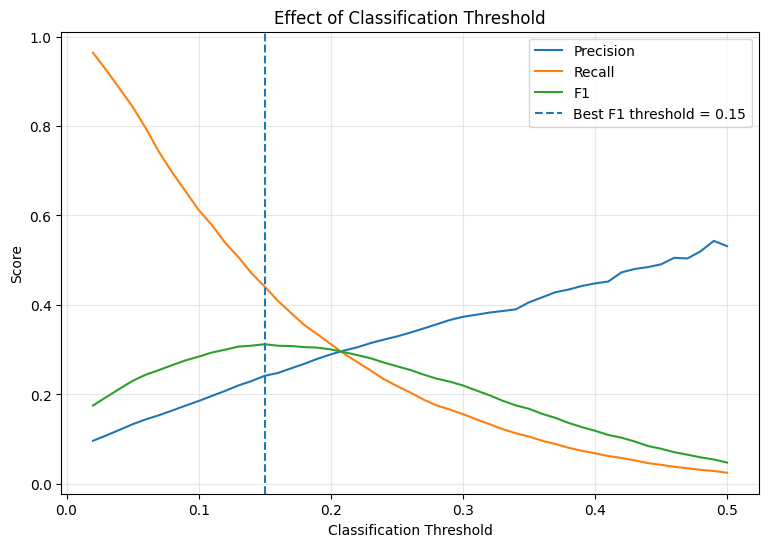

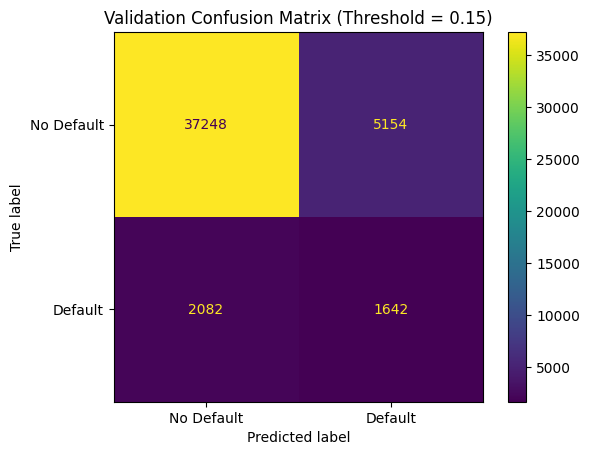

Selected threshold based on maximum F1:
Threshold: 0.15
F1:        0.3122
Precision: 0.2416
Recall:    0.4409
Balanced accuracy: 0.6597


In [90]:
# One comprehensive visualization + confusion matrix

import matplotlib.pyplot as plt

# -----------------------------------
# Precision / Recall / F1 by threshold
# -----------------------------------

plt.figure(figsize=(9, 6))

plt.plot(
    threshold_df["threshold"],
    threshold_df["precision"],
    label="Precision"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["recall"],
    label="Recall"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["f1"],
    label="F1"
)

plt.axvline(
    best_f1_row["threshold"],
    linestyle="--",
    label=f"Best F1 threshold = {best_f1_row['threshold']:.2f}"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Effect of Classification Threshold")
plt.legend()
plt.grid(alpha=0.3)

plt.show()


# -----------------------------------
# Confusion matrix at best F1 threshold
# -----------------------------------

best_threshold = best_f1_row["threshold"]

best_predictions = (
    val_prob >= best_threshold
).astype(int)

ConfusionMatrixDisplay.from_predictions(
    y_val,
    best_predictions,
    display_labels=[
        "No Default",
        "Default"
    ]
)

plt.title(
    f"Validation Confusion Matrix "
    f"(Threshold = {best_threshold:.2f})"
)

plt.show()


print("Selected threshold based on maximum F1:")
print(f"Threshold: {best_threshold:.2f}")
print(f"F1:        {best_f1_row['f1']:.4f}")
print(f"Precision: {best_f1_row['precision']:.4f}")
print(f"Recall:    {best_f1_row['recall']:.4f}")
print(
    f"Balanced accuracy: "
    f"{best_f1_row['balanced_accuracy']:.4f}"
)

In [91]:
# Flexible network and training function

class FlexibleNN(nn.Module):
    def __init__(self, input_size, hidden_sizes, dropout=0.2):
        super().__init__()

        layers = []
        previous_size = input_size

        for hidden_size in hidden_sizes:
            layers.append(nn.Linear(previous_size, hidden_size))
            layers.append(nn.ReLU())
            layers.append(nn.Dropout(dropout))
            previous_size = hidden_size

        layers.append(nn.Linear(previous_size, 1))

        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)


def train_architecture(
    train_loader,
    val_loader,
    input_size,
    hidden_sizes,
    dropout=0.2,
    weight_decay=1e-4,
    learning_rate=0.001,
    epochs=30,
    patience=4,
):
    set_seed()

    model = FlexibleNN(
        input_size=input_size,
        hidden_sizes=hidden_sizes,
        dropout=dropout
    ).to(device)

    criterion = nn.BCEWithLogitsLoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate,
        weight_decay=weight_decay
    )

    best_auc = -np.inf
    best_state = None
    history = []

    epochs_without_improvement = 0

    for epoch in range(1, epochs + 1):

        # Train
        model.train()
        total_loss = 0

        for X_batch, y_batch in train_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            optimizer.zero_grad()

            logits = model(X_batch)
            loss = criterion(logits, y_batch)

            loss.backward()
            optimizer.step()

            total_loss += loss.item() * len(X_batch)

        train_loss = total_loss / len(train_loader.dataset)

        # Validate
        y_val, val_prob = get_probabilities(
            model,
            val_loader
        )

        roc_auc = roc_auc_score(y_val, val_prob)
        pr_auc = average_precision_score(y_val, val_prob)

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "roc_auc": roc_auc,
            "pr_auc": pr_auc
        })

        print(
            f"Epoch {epoch:02d} | "
            f"Loss: {train_loss:.4f} | "
            f"Val AUC: {roc_auc:.4f}"
        )

        # Early stopping based on ROC-AUC
        if roc_auc > best_auc:
            best_auc = roc_auc
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= patience:
            print(f"Early stopping at epoch {epoch}")
            break

    # Restore best model
    model.load_state_dict(best_state)

    return model, pd.DataFrame(history)


def count_parameters(model):
    return sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

In [92]:
# Run the architecture comparison

architectures = {
    "Smaller 64-32": [64, 32],
    "Current 128-64": [128, 64],
    "Deeper 128-64-32": [128, 64, 32],
    "Wider 256-128": [256, 128],
}

architecture_results = []
architecture_models = {}
architecture_histories = {}

for name, hidden_sizes in architectures.items():

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    model, history = train_architecture(
        train_loader=train_loader,
        val_loader=val_loader,
        input_size=input_size,
        hidden_sizes=hidden_sizes,

        # Keep winning settings fixed
        dropout=0.2,
        weight_decay=1e-4,
        learning_rate=0.001,
        epochs=30,
        patience=4
    )

    best_row = history.loc[
        history["roc_auc"].idxmax()
    ]

    # Evaluate restored best model
    y_val, val_prob = get_probabilities(
        model,
        val_loader
    )

    # Report classification metrics at our chosen threshold
    threshold_metrics = metrics_at_threshold(
        y_val,
        val_prob,
        threshold=0.15
    )

    architecture_models[name] = model
    architecture_histories[name] = history

    architecture_results.append({
        "model": name,
        "hidden_layers": str(hidden_sizes),
        "parameters": count_parameters(model),
        "best_epoch": int(best_row["epoch"]),
        "roc_auc": best_row["roc_auc"],
        "pr_auc": best_row["pr_auc"],
        "accuracy_at_0.15": threshold_metrics["accuracy"],
        "f1_at_0.15": threshold_metrics["f1"],
        "precision_at_0.15": threshold_metrics["precision"],
        "recall_at_0.15": threshold_metrics["recall"],
    })


architecture_results_df = (
    pd.DataFrame(architecture_results)
    .sort_values("roc_auc", ascending=False)
    .reset_index(drop=True)
)

architecture_results_df


Smaller 64-32
Epoch 01 | Loss: 0.2986 | Val AUC: 0.7497
Epoch 02 | Loss: 0.2523 | Val AUC: 0.7561
Epoch 03 | Loss: 0.2501 | Val AUC: 0.7575
Epoch 04 | Loss: 0.2496 | Val AUC: 0.7582
Epoch 05 | Loss: 0.2484 | Val AUC: 0.7587
Epoch 06 | Loss: 0.2482 | Val AUC: 0.7596
Epoch 07 | Loss: 0.2472 | Val AUC: 0.7604
Epoch 08 | Loss: 0.2468 | Val AUC: 0.7610
Epoch 09 | Loss: 0.2465 | Val AUC: 0.7617
Epoch 10 | Loss: 0.2464 | Val AUC: 0.7620
Epoch 11 | Loss: 0.2459 | Val AUC: 0.7613
Epoch 12 | Loss: 0.2455 | Val AUC: 0.7612
Epoch 13 | Loss: 0.2451 | Val AUC: 0.7622
Epoch 14 | Loss: 0.2452 | Val AUC: 0.7624
Epoch 15 | Loss: 0.2449 | Val AUC: 0.7619
Epoch 16 | Loss: 0.2444 | Val AUC: 0.7622
Epoch 17 | Loss: 0.2441 | Val AUC: 0.7621
Epoch 18 | Loss: 0.2438 | Val AUC: 0.7621
Early stopping at epoch 18

Current 128-64
Epoch 01 | Loss: 0.2785 | Val AUC: 0.7532
Epoch 02 | Loss: 0.2496 | Val AUC: 0.7566
Epoch 03 | Loss: 0.2483 | Val AUC: 0.7586
Epoch 04 | Loss: 0.2470 | Val AUC: 0.7583
Epoch 05 | Loss: 0

,model,hidden_layers,parameters,best_epoch,roc_auc,pr_auc,accuracy_at_0.15,f1_at_0.15,precision_at_0.15,recall_at_0.15
0,Deeper 128-64-32,"[128, 64, 32]",35969,8,0.763632,0.248511,0.838377,0.310042,0.236549,0.449785
1,Wider 256-128,"[256, 128]",84225,12,0.763411,0.247868,0.851906,0.309232,0.248013,0.410580
2,Current 128-64,"[128, 64]",33921,15,0.762853,0.246222,0.843125,0.312167,0.241613,0.440924
3,Smaller 64-32,"[64, 32]",14913,14,0.762371,0.246148,0.848459,0.310107,0.245162,0.421858


Best architecture:
model                Deeper 128-64-32
hidden_layers           [128, 64, 32]
parameters                      35969
best_epoch                          8
roc_auc                      0.763632
pr_auc                       0.248511
accuracy_at_0.15             0.838377
f1_at_0.15                   0.310042
precision_at_0.15            0.236549
recall_at_0.15               0.449785
Name: 0, dtype: object


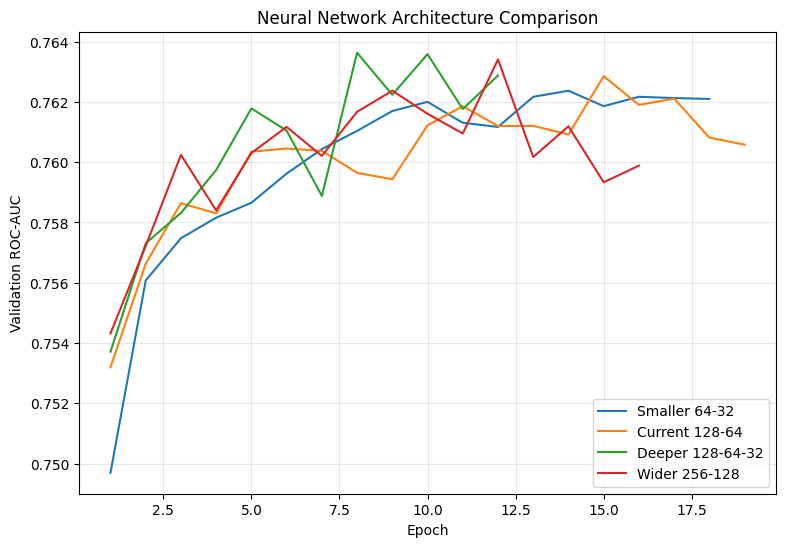

In [93]:
# Identify the winner and visualize performance

best_architecture = architecture_results_df.iloc[0]

print("Best architecture:")
print(best_architecture)

plt.figure(figsize=(9, 6))

for name, history in architecture_histories.items():
    plt.plot(
        history["epoch"],
        history["roc_auc"],
        label=name
    )

plt.xlabel("Epoch")
plt.ylabel("Validation ROC-AUC")
plt.title("Neural Network Architecture Comparison")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

## Phase 11: Error Analysis

In [99]:
# Build the validation error table

FINAL_MODEL_NAME = "Deeper 128-64-32"
DECISION_THRESHOLD = 0.15
RANDOM_STATE = 42

final_model = architecture_models[FINAL_MODEL_NAME]

# Make sure we have the stratified validation data
train_loader, val_loader, strat_data = make_loaders("stratified")

# Get probabilities from the final model
y_val, val_prob = get_probabilities(
    final_model,
    val_loader
)

y_pred = (val_prob >= DECISION_THRESHOLD).astype(int)

# Original row indices corresponding to validation observations
val_indices = np.asarray(strat_data["indices"]["val"])

assert len(val_indices) == len(y_val)

# Build a review dataframe using the original applicant-level data
validation_review = model_df.loc[val_indices].copy()

validation_review["pred_probability"] = val_prob
validation_review["predicted_default"] = y_pred
validation_review["correct_prediction"] = (
    validation_review[TARGET].to_numpy() == y_pred
)

# Label each type of prediction
conditions = [
    (validation_review[TARGET] == 1) &
    (validation_review["predicted_default"] == 1),

    (validation_review[TARGET] == 0) &
    (validation_review["predicted_default"] == 0),

    (validation_review[TARGET] == 1) &
    (validation_review["predicted_default"] == 0),

    (validation_review[TARGET] == 0) &
    (validation_review["predicted_default"] == 1),
]

labels = [
    "true_positive",
    "true_negative",
    "false_negative",
    "false_positive",
]

validation_review["prediction_type"] = np.select(
    conditions,
    labels,
    default="unknown"
)

# Summary of prediction outcomes
error_summary = (
    validation_review["prediction_type"]
    .value_counts()
    .rename_axis("prediction_type")
    .reset_index(name="count")
)

error_summary["percent"] = (
    error_summary["count"] /
    len(validation_review)
)

display(error_summary)

print(
    f"\nOverall validation error rate: "
    f"{1 - validation_review['correct_prediction'].mean():.3%}"
)

,prediction_type,count,percent
0,true_negative,36996,0.802064
1,false_positive,5406,0.117201
2,false_negative,2049,0.044422
3,true_positive,1675,0.036314



Overall validation error rate: 16.162%


In [100]:
# Create eyeball and blackbox validation sets

rng = np.random.default_rng(RANDOM_STATE)

EYEBALL_SIZE = 5000
MANUAL_ERROR_SAMPLE_SIZE = 100

all_positions = np.arange(len(validation_review))

eyeball_positions = rng.choice(
    all_positions,
    size=EYEBALL_SIZE,
    replace=False
)

blackbox_positions = np.setdiff1d(
    all_positions,
    eyeball_positions
)

eyeball_df = validation_review.iloc[
    eyeball_positions
].copy()

blackbox_df = validation_review.iloc[
    blackbox_positions
].copy()


# ---------------------------------------------------------
# Manual error sample
# ---------------------------------------------------------

eyeball_errors = eyeball_df[
    ~eyeball_df["correct_prediction"]
].copy()

manual_errors = eyeball_errors.sample(
    n=min(MANUAL_ERROR_SAMPLE_SIZE, len(eyeball_errors)),
    random_state=RANDOM_STATE
).copy()


# ---------------------------------------------------------
# Blackbox metrics
# ---------------------------------------------------------

blackbox_y = blackbox_df[TARGET].to_numpy()
blackbox_prob = blackbox_df["pred_probability"].to_numpy()

blackbox_metrics = metrics_at_threshold(
    blackbox_y,
    blackbox_prob,
    threshold=DECISION_THRESHOLD
)

blackbox_metrics.update({
    "roc_auc": roc_auc_score(
        blackbox_y,
        blackbox_prob
    ),
    "pr_auc": average_precision_score(
        blackbox_y,
        blackbox_prob
    )
})

blackbox_metrics_df = pd.DataFrame(
    [blackbox_metrics]
)


print("Eyeball validation rows:", len(eyeball_df))
print("Eyeball errors:", len(eyeball_errors))
print("Manual errors selected:", len(manual_errors))
print("Blackbox validation rows:", len(blackbox_df))

display(blackbox_metrics_df)

Eyeball validation rows: 5000
Eyeball errors: 778
Manual errors selected: 100
Blackbox validation rows: 41126


,threshold,accuracy,balanced_accuracy,f1,precision,recall,specificity,tn,fp,fn,tp,roc_auc,pr_auc
0,0.15,0.837645,0.660821,0.311579,0.238441,0.449435,0.872206,32938,4826,1851,1511,0.76334,0.251695


In [96]:
%pip install openpyxl

Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [openpyxl]
Note: you may need to restart the kernel to use updated packages.


In [97]:
# Create the error-analysis spreadsheet

review_feature_candidates = [
    # Identification / outcome
    "SK_ID_CURR",
    TARGET,

    # Demographics / household
    "CODE_GENDER",
    "AGE_YEARS",
    "CNT_CHILDREN",
    "CNT_FAM_MEMBERS",
    "NAME_FAMILY_STATUS",
    "NAME_EDUCATION_TYPE",
    "NAME_INCOME_TYPE",
    "OCCUPATION_TYPE",
    "NAME_HOUSING_TYPE",

    # Financial information
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "AMT_GOODS_PRICE",

    # External risk scores
    "EXT_SOURCE_1",
    "EXT_SOURCE_2",
    "EXT_SOURCE_3",
    "EXT_SOURCE_MEAN",

    # Engineered ratios
    "CREDIT_INCOME_RATIO",
    "ANNUITY_INCOME_RATIO",
    "INCOME_PER_PERSON",

    # Geographic / regional information
    "REGION_RATING_CLIENT",
    "REGION_RATING_CLIENT_W_CITY",

    # Bureau history, if these exist
    "BUREAU_LOAN_COUNT",
    "BUREAU_ACTIVE_COUNT",
    "BUREAU_CREDIT_SUM",
    "BUREAU_DEBT_SUM",
]

# Only use columns that actually exist
review_features = [
    col for col in review_feature_candidates
    if col in manual_errors.columns
]

# Prediction information always comes first
prediction_columns = [
    "pred_probability",
    "predicted_default",
    "prediction_type",
]

spreadsheet_df = manual_errors[
    review_features + prediction_columns
].copy()


# ---------------------------------------------------------
# Blank columns for manual review
# ---------------------------------------------------------

spreadsheet_df["reviewed"] = ""
spreadsheet_df["manual_category"] = ""
spreadsheet_df["possible_reason"] = ""
spreadsheet_df["possible_improvement"] = ""
spreadsheet_df["notes"] = ""


# Put the most useful fields first
front_columns = [
    c for c in [
        "SK_ID_CURR",
        TARGET,
        "pred_probability",
        "predicted_default",
        "prediction_type",
    ]
    if c in spreadsheet_df.columns
]

other_columns = [
    c for c in spreadsheet_df.columns
    if c not in front_columns
]

spreadsheet_df = spreadsheet_df[
    front_columns + other_columns
]


# ---------------------------------------------------------
# Eyeball-set error summary
# ---------------------------------------------------------

eyeball_error_summary = (
    eyeball_df["prediction_type"]
    .value_counts()
    .rename_axis("prediction_type")
    .reset_index(name="count")
)

eyeball_error_summary["percent"] = (
    eyeball_error_summary["count"] /
    len(eyeball_df)
)


# ---------------------------------------------------------
# Modeling iteration log
# ---------------------------------------------------------

iteration_log = pd.DataFrame([
    {
        "iteration": "Baseline NN",
        "change": "128-64 network, no regularization",
        "validation_roc_auc": 0.759942,
        "decision": "Overfitting observed"
    },
    {
        "iteration": "Regularized NN",
        "change": "Dropout 0.2 + L2 1e-4",
        "validation_roc_auc": 0.762853,
        "decision": "Improved generalization; retained"
    },
    {
        "iteration": "Deeper NN",
        "change": "128-64-32 with dropout 0.2 + L2 1e-4",
        "validation_roc_auc": 0.763632,
        "decision": "Best ROC-AUC; selected as current model"
    }
])


# ---------------------------------------------------------
# Instructions sheet
# ---------------------------------------------------------

instructions = pd.DataFrame({
    "field": [
        "reviewed",
        "manual_category",
        "possible_reason",
        "possible_improvement",
        "notes"
    ],
    "what_to_enter": [
        "Yes after examining the applicant",
        "Short category describing the main pattern in the error",
        "Why you think the model may have made this mistake",
        "Feature/model/data change that might address the error",
        "Any additional observations"
    ]
})


# ---------------------------------------------------------
# Export workbook
# ---------------------------------------------------------

ERROR_ANALYSIS_FILE = "mortgage_error_analysis.xlsx"

with pd.ExcelWriter(ERROR_ANALYSIS_FILE) as writer:

    spreadsheet_df.to_excel(
        writer,
        sheet_name="eyeball_errors",
        index=False
    )

    eyeball_error_summary.to_excel(
        writer,
        sheet_name="eyeball_summary",
        index=False
    )

    blackbox_metrics_df.to_excel(
        writer,
        sheet_name="blackbox_metrics",
        index=False
    )

    iteration_log.to_excel(
        writer,
        sheet_name="iteration_log",
        index=False
    )

    instructions.to_excel(
        writer,
        sheet_name="instructions",
        index=False
    )


print(
    f"Error-analysis spreadsheet saved as: "
    f"{ERROR_ANALYSIS_FILE}"
)

display(spreadsheet_df.head())

Error-analysis spreadsheet saved as: mortgage_error_analysis.xlsx


,SK_ID_CURR,TARGET,pred_probability,predicted_default,prediction_type,CODE_GENDER,AGE_YEARS,CNT_CHILDREN,CNT_FAM_MEMBERS,NAME_FAMILY_STATUS,...,EXT_SOURCE_MEAN,CREDIT_INCOME_RATIO,ANNUITY_INCOME_RATIO,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,reviewed,manual_category,possible_reason,possible_improvement,notes
265998,408138,0,0.169122,1,false_positive,M,34.932238,0,2.0,Married,...,0.301929,5.267200,0.205560,3,1,,,,,
217132,351579,0,0.272458,1,false_positive,F,45.656400,0,1.0,Single / not married,...,0.369847,2.343880,0.157800,3,3,,,,,
104119,220844,1,0.069531,0,false_negative,M,44.183436,0,2.0,Civil marriage,...,0.380819,5.479778,0.147578,2,2,,,,,
210629,344085,0,0.495799,1,false_positive,M,48.199863,0,2.0,Civil marriage,...,0.273772,3.670303,0.179394,2,2,,,,,
92029,206868,1,0.109210,0,false_negative,M,37.645448,1,3.0,Civil marriage,...,0.434420,1.730286,0.106686,2,2,,,,,


In [98]:
# ---------------------------------------------------------
# SUMMARIZE COMPLETED MANUAL ERROR ANALYSIS
# Run this AFTER editing and saving the Excel spreadsheet
# ---------------------------------------------------------

reviewed_errors = pd.read_excel(
    ERROR_ANALYSIS_FILE,
    sheet_name="eyeball_errors"
)

# Keep only rows where a manual category was entered
completed_reviews = reviewed_errors[
    reviewed_errors["manual_category"].notna()
    &
    (
        reviewed_errors["manual_category"]
        .astype(str)
        .str.strip() != ""
    )
].copy()

print(
    f"Manually reviewed: "
    f"{len(completed_reviews)} / {len(reviewed_errors)}"
)


if len(completed_reviews) > 0:

    category_summary = (
        completed_reviews
        .groupby(
            ["prediction_type", "manual_category"]
        )
        .size()
        .reset_index(name="count")
        .sort_values(
            "count",
            ascending=False
        )
    )

    category_summary["percent_of_reviewed"] = (
        category_summary["count"] /
        len(completed_reviews)
    )

    display(category_summary)

else:
    print(
        "No manual categories have been entered yet."
    )

Manually reviewed: 0 / 100
No manual categories have been entered yet.
